# Nettoyage

In [ ]:
import pandas as pd
import numpy as np
import os
import plotly.express as px
import warnings
warnings.filterwarnings("ignore")

In [ ]:
CONFIG = {
    "nom": "CSE-CIC-IDS2018 – Détection d'intrusion réseau (infrastructure AWS)",

    "base_url": "https://cse-cic-ids2018.s3.ca-central-1.amazonaws.com/Processed%20Traffic%20Data%20for%20ML%20Algorithms/",

    "jours": {
        "Wednesday-14-02-2018_TrafficForML_CICFlowMeter.csv": "Force brute FTP/SSH",
        "Friday-16-02-2018_TrafficForML_CICFlowMeter.csv":    "DoS Hulk / SlowHTTPTest",
        "Friday-02-03-2018_TrafficForML_CICFlowMeter.csv":    "Botnet",
    },

    "frac": 0.015,
    "random_state": 42,
    "cache": "/content/ids2018_echantillon.parquet",

    "classe_negative": "Benign",

    "colonnes_a_retirer": ["Timestamp", "Dst Port", "Flow ID", "Src IP", "Src Port", "Dst IP"],
}

print(CONFIG["nom"])
print(f"{len(CONFIG['jours'])} journées sélectionnées")

CSE-CIC-IDS2018 – Détection d'intrusion réseau (infrastructure AWS)
3 journées sélectionnées


In [ ]:
if os.path.exists(CONFIG["cache"]):
    brut = pd.read_parquet(CONFIG["cache"])
    print("Échantillon rechargé depuis le cache")
else:
    print("Premier chargement depuis AWS S3 (quelques minutes)...")
    brut = pd.concat(
        [charger_jour(f, CONFIG["frac"], CONFIG["random_state"]) for f in CONFIG["jours"]],
        ignore_index=True,
    )
    brut.to_parquet(CONFIG["cache"])
    print("Cache sauvegardé")

print(brut.shape)
brut["Label"].value_counts()

Premier chargement depuis AWS S3 (quelques minutes)...
  morceau 6 lu (1,200,000 lignes)
Wednesday-14-02-2018 : 15,729 flux gardés
  morceau 6 lu (1,200,000 lignes)
Friday-16-02-2018 : 15,729 flux gardés
  morceau 6 lu (1,200,000 lignes)
Friday-02-03-2018 : 15,729 flux gardés
Cache sauvegardé
(47187, 81)


,count
Label,
Benign,28260
DoS attacks-Hulk,6978
Bot,4232
FTP-BruteForce,2883
SSH-Bruteforce,2802
DoS attacks-SlowHTTPTest,2032


In [ ]:
from google.colab import drive

try:
    print("Attempting to mount Google Drive...")
    drive.mount("/content/drive")
    os.makedirs("/content/drive/MyDrive/projet_xai", exist_ok=True)
    CONFIG["cache"] = "/content/drive/MyDrive/projet_xai/ids2018_echantillon.parquet"
except Exception as e:
    print(f"Could not mount Google Drive ({e}). Falling back to local runtime storage.")
    CONFIG["cache"] = "/content/ids2018_echantillon.parquet"

print("Cache path set to:", CONFIG["cache"])

Attempting to mount Google Drive...
Mounted at /content/drive
Cache path set to: /content/drive/MyDrive/projet_xai/ids2018_echantillon.parquet


In [ ]:
def charger_jour(nom_fichier, frac, random_state=42, chunksize=200_000):
    """Lit un CSV depuis S3 par morceaux et garde un échantillon aléatoire de chaque morceau."""
    url = CONFIG["base_url"] + nom_fichier
    rng = np.random.RandomState(random_state)
    morceaux = []

    for i, chunk in enumerate(pd.read_csv(url, chunksize=chunksize, dtype=str)):
        chunk = chunk[chunk["Label"] != "Label"]
        morceaux.append(chunk.sample(frac=frac, random_state=rng))
        print(f"  morceau {i+1} lu ({(i+1)*chunksize:,} lignes)", end="\r")

    df = pd.concat(morceaux, ignore_index=True)
    df["jour"] = nom_fichier.split("_")[0]
    print(f"\n{df['jour'].iloc[0]} : {len(df):,} flux gardés")
    return df

In [ ]:
#Retirer les colonnes écartées et convertir en nombres
df = brut.copy().reset_index(drop=True)

df = df.drop(columns=[c for c in CONFIG["colonnes_a_retirer"] if c in df.columns])

for c in df.columns:
    if c not in ["Label", "jour"]:
        df[c] = pd.to_numeric(df[c], errors="coerce")

print(df.shape)
print(df.dtypes.value_counts())

(47187, 79)
int64      41
float64    36
object      2
Name: count, dtype: int64


In [ ]:
#valeurs infinies remplacées par nan
num_cols = df.select_dtypes(include="number").columns

nb_inf = np.isinf(df[num_cols]).sum()
print("Valeurs infinies par colonne :")
print(nb_inf[nb_inf > 0])

df = df.replace([np.inf, -np.inf], np.nan)

manq = df.isna().sum()
print("\nValeurs manquantes après remplacement :")
print(manq[manq > 0])

Valeurs infinies par colonne :
Flow Byts/s     54
Flow Pkts/s    127
dtype: int64

Valeurs manquantes après remplacement :
Flow Byts/s    127
Flow Pkts/s    127
dtype: int64


D’où viennent les infinis ? Les colonnes de débit (Flow Byts/s, Flow Pkts/s) sont calculées ainsi : quantité ÷ durée du flux. Quand un flux dure 0 microseconde, la division donne l’infini.

In [ ]:
#colonnes constantes
constantes = [c for c in num_cols if df[c].nunique(dropna=False) <= 1]
print(f"{len(constantes)} colonnes constantes :")
print(constantes)

df = df.drop(columns=constantes)
print("\nShape :", df.shape)

10 colonnes constantes :
['Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'CWE Flag Count', 'Fwd Byts/b Avg', 'Fwd Pkts/b Avg', 'Fwd Blk Rate Avg', 'Bwd Byts/b Avg', 'Bwd Pkts/b Avg', 'Bwd Blk Rate Avg']

Shape : (47187, 69)


In [ ]:
feat_cols = [c for c in df.columns if c not in ["Label", "jour"]]

#hash par ligne :calculée sur les variables uniquement
cle = pd.util.hash_pandas_object(df[feat_cols], index=False).values

#Doublons : flux strictement identiques.
stats = (pd.DataFrame({"Label": df["Label"], "doublon": pd.Series(cle).duplicated()})
           .groupby("Label")["doublon"].agg(nb_doublons="sum", pct="mean"))
stats["pct"] = (stats["pct"] * 100).round(1)
print("Doublons par étiquette :")
display(stats)

#Conflits : flux identiques avec des étiquettes différentes
nb_labels = df.groupby(cle)["Label"].transform("nunique")
conflits = df[nb_labels > 1]
print(f"\nLignes en conflit : {len(conflits):,}")
if len(conflits):
    print(conflits.groupby(cle[nb_labels > 1])["Label"]
          .agg(lambda s: " + ".join(sorted(s.unique()))).value_counts())

Doublons par étiquette :


,nb_doublons,pct
Label,,
Benign,1081,3.8
Bot,1670,39.5
DoS attacks-Hulk,781,11.2
DoS attacks-SlowHTTPTest,2004,98.6
FTP-BruteForce,2850,98.9
SSH-Bruteforce,1406,50.2



Lignes en conflit : 3,523
Label
DoS attacks-SlowHTTPTest + FTP-BruteForce    8
Name: count, dtype: int64


In [ ]:
avant = len(df)
df = df.loc[~pd.Series(cle).duplicated().values].reset_index(drop=True)

print(f"Lignes supprimées : {avant - len(df):,} ({(avant - len(df)) / avant:.1%})")
print(f"Lignes restantes : {len(df):,}\n")
print(df["Label"].value_counts())
print(f"\nTaux d'attaque : {(df['Label'] != 'Benign').mean():.1%}")

Lignes supprimées : 9,792 (20.8%)
Lignes restantes : 37,395

Label
Benign                      27179
DoS attacks-Hulk             6197
Bot                          2562
SSH-Bruteforce               1396
FTP-BruteForce                 33
DoS attacks-SlowHTTPTest       28
Name: count, dtype: int64

Taux d'attaque : 27.3%


In [ ]:
df["type_attaque"] = df["Label"]                                          # détail, pour l'analyse
df["_y"] = (df["Label"] != CONFIG["classe_negative"]).astype(int)         # binaire : 1 = attaque
df["Protocol"] = df["Protocol"].astype("Int64").astype(str)

df = df.drop(columns=["Label"])

print(df.shape)
print(df["_y"].value_counts())
display(pd.crosstab(df["jour"], df["type_attaque"]))

#Sauvegarde des données nettoyées
CONFIG["cache_propre"] = CONFIG["cache"].replace("echantillon", "propre")
df.to_parquet(CONFIG["cache_propre"], index=False)
print("Sauvegardé :", CONFIG["cache_propre"])

(37395, 70)
_y
0    27179
1    10216
Name: count, dtype: int64


type_attaque,Benign,Bot,DoS attacks-Hulk,DoS attacks-SlowHTTPTest,FTP-BruteForce,SSH-Bruteforce
jour,,,,,,
Friday-02-03-2018,10985,2562,0,0,0,0
Friday-16-02-2018,6719,0,6197,28,0,0
Wednesday-14-02-2018,9475,0,0,0,33,1396


Sauvegardé : /content/drive/MyDrive/projet_xai/ids2018_propre.parquet


In [ ]:
exclues = ["_y", "type_attaque", "jour"]
num_cols = [c for c in df.select_dtypes(include="number").columns if c not in exclues]
cat_cols = [c for c in df.select_dtypes(exclude="number").columns if c not in exclues]

print(f"{len(df):,} flux | {len(num_cols)} variables numériques | catégorielles : {cat_cols}")
display(df.head())

stats = df[num_cols].describe().T
stats["asymetrie"] = df[num_cols].skew()
stats = stats.sort_values("asymetrie", ascending=False)
display(stats.round(2).head(15))

37,395 flux | 66 variables numériques | catégorielles : ['Protocol']


,Protocol,Flow Duration,Tot Fwd Pkts,Tot Bwd Pkts,TotLen Fwd Pkts,TotLen Bwd Pkts,Fwd Pkt Len Max,Fwd Pkt Len Min,Fwd Pkt Len Mean,Fwd Pkt Len Std,...,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,jour,type_attaque,_y
0,6,1,1,1,0,0,0,0,0.000000,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Wednesday-14-02-2018,FTP-BruteForce,1
1,6,2,1,1,0,0,0,0,0.000000,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Wednesday-14-02-2018,FTP-BruteForce,1
2,6,5,1,1,0,0,0,0,0.000000,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Wednesday-14-02-2018,FTP-BruteForce,1
3,6,3,1,1,0,0,0,0,0.000000,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Wednesday-14-02-2018,FTP-BruteForce,1
4,6,377177,23,20,1928,2665,640,0,83.826087,135.847392,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Wednesday-14-02-2018,SSH-Bruteforce,1


,count,mean,std,min,25%,50%,75%,max,asymetrie
Subflow Bwd Byts,37395.0,2595.07,81620.52,0.0,0.0,152.00,488.00,10275475.0,101.71
TotLen Bwd Pkts,37395.0,2595.07,81620.52,0.0,0.0,152.00,488.00,10275475.0,101.71
Subflow Bwd Pkts,37395.0,5.39,57.28,0.0,0.0,3.00,4.00,7099.0,97.27
Tot Bwd Pkts,37395.0,5.39,57.28,0.0,0.0,3.00,4.00,7099.0,97.27
Bwd Header Len,37395.0,130.73,1149.73,0.0,0.0,92.00,136.00,142004.0,96.18
Tot Fwd Pkts,37395.0,5.76,24.75,1.0,2.0,3.00,5.00,2901.0,90.55
Subflow Fwd Pkts,37395.0,5.76,24.75,1.0,2.0,3.00,5.00,2901.0,90.55
Fwd Header Len,37395.0,142.70,607.14,0.0,40.0,72.00,168.00,73196.0,87.32
Active Min,37395.0,44967.33,939331.57,0.0,0.0,0.00,0.00,84900000.0,63.50
Bwd Pkts/s,37395.0,2078.27,33490.66,0.0,0.0,0.90,61.05,2000000.0,47.92


skew() : mesure l’asymétrie de la distribution

* environ 0 : distribution symétrique, comme une courbe en cloche ;
* très positive (> 2) : la plupart des valeurs sont petites, avec quelques valeurs énormes à droite. C’est ce qu’on appelle une queue lourde.





### Analyse – Vue d'ensemble

- **37 395 flux** après nettoyage, **66 variables numériques** et 1 variable catégorielle (`Protocol`).
- **Valeurs manquantes :** seulement 64 dans `Flow Byts/s` et `Flow Pkts/s`. Ce sont des flux de durée 0 (débit = quantité ÷ 0). Elles seront imputées au module 2.
- **Colonnes en double :** certaines variables sont strictement identiques (`Subflow Fwd Pkts` = `Tot Fwd Pkts`, `Subflow Bwd Byts` = `TotLen Bwd Pkts`…). CICFlowMeter les calcule deux fois sous deux noms. Elles seront retirées au module 2.
- **Distributions très asymétriques :** pour la plupart des variables, le maximum est des milliers de fois plus grand que la médiane (asymétrie jusqu'à 100). Exemple : `TotLen Bwd Pkts` a une médiane de 152 octets et un maximum de 10 millions.
  → Une **transformation log** sera nécessaire pour la régression logistique et KNN. Les modèles à base d'arbres n'y sont pas sensibles.
- **Variables creuses :** les variables `Active ...` valent 0 pour plus de 75 % des flux.

In [ ]:
variables_cles = ["Flow Duration", "Tot Fwd Pkts", "Tot Bwd Pkts", "TotLen Fwd Pkts",
                  "Flow Pkts/s", "Flow IAT Mean", "Init Fwd Win Byts", "Init Bwd Win Byts"]
variables_cles = [v for v in variables_cles if v in df.columns]

display(df.groupby("type_attaque")[variables_cles].median().T.round(1))

type_attaque,Benign,Bot,DoS attacks-Hulk,DoS attacks-SlowHTTPTest,FTP-BruteForce,SSH-Bruteforce
Flow Duration,2206955.0,10634.0,17965.0,23.5,17.0,373879.5
Tot Fwd Pkts,5.0,3.0,2.0,1.0,1.0,22.0
Tot Bwd Pkts,3.0,4.0,0.0,1.0,1.0,22.0
TotLen Fwd Pkts,364.0,326.0,0.0,0.0,0.0,1928.0
Flow Pkts/s,6.7,659.3,126.0,85144.9,117647.1,117.8
Flow IAT Mean,161968.8,1769.6,15630.0,23.5,17.0,8682.0
Init Fwd Win Byts,237.0,8192.0,225.0,26883.0,26883.0,26883.0
Init Bwd Win Byts,211.0,219.0,-1.0,0.0,0.0,230.0


### Analyse – Comparaison des médianes par type de flux

**Benign — trafic humain normal**
- Flux longs (≈ 2,2 s), rythme lent (6,7 paquets/s).

**Bot — beaconing**
- Flux courts (≈ 10 ms), quelques paquets dans chaque sens.
- La machine infectée contacte régulièrement son serveur de commande.

**DoS Hulk — le serveur ne répond plus**
- 0 paquet retour, `Init Bwd Win = -1` (aucune réponse du serveur).
- Signe d'un déni de service réussi.

**SSH-Bruteforce — vraies sessions SSH**
- 22 paquets dans chaque sens, ≈ 2 Ko échangés.
- Échange de clés puis tentative d'authentification.

**FTP-BruteForce / SlowHTTPTest — connexions vides**
- ≈ 20 µs, 1 paquet, 0 octet de données.
- Connexions refusées immédiatement par le serveur.

---

**Points critiques :**

1. **Incohérence d'étiquetage :** SlowHTTPTest devrait produire des flux *longs* (son principe est de garder les connexions ouvertes), alors qu'on observe des flux de 23 µs, identiques aux flux FTP. Avec les conflits d'étiquettes détectés à l'étape 4, cela indique que ces flux ne correspondent pas à leur étiquette.

2. **Raccourci potentiel – `Init Fwd Win Byts` :** FTP, SlowHTTPTest et SSH ont tous exactement **26 883**, et Bot **8 192** (valeur typique de Windows). Cette variable identifie probablement **la machine de l'attaquant**, pas le comportement d'attaque.
   → Au module 5, on comparera le modèle **avec et sans** cette variable pour vérifier s'il s'appuie sur ce raccourci.

**visualisation**

In [ ]:
COULEURS = {"Normal": "#4C78A8", "Attaque": "#E45756"}
classe = df["_y"].map({0: "Normal", 1: "Attaque"})
c = classe.value_counts().reset_index()
c.columns = ["classe", "nb"]
fig = px.pie(c, names="classe", values="nb", hole=0.4, color="classe",
             color_discrete_map=COULEURS, title="Répartition Normal / Attaque")
fig.update_traces(textinfo="percent+value")
fig.show()
t = df["type_attaque"].value_counts().reset_index()
t.columns = ["type_attaque", "nb"]
fig = px.bar(t.sort_values("nb"), x="nb", y="type_attaque", orientation="h",
             text="nb", log_x=True, title="Nombre de flux par type (échelle log)")
fig.show()

In [ ]:
def log_signe(x):
    """log(1+|x|) en gardant le signe (gère les valeurs -1)."""
    return np.sign(x) * np.log1p(np.abs(x))

variables_cles = ["Flow Duration", "Tot Fwd Pkts", "TotLen Fwd Pkts",
                  "Flow Pkts/s", "Flow IAT Mean", "Init Fwd Win Byts"]
variables_cles = [v for v in variables_cles if v in df.columns]

for v in variables_cles:
    tmp = pd.DataFrame({f"log({v})": log_signe(df[v]), "classe": classe}).dropna()
    fig = px.histogram(tmp, x=f"log({v})", color="classe", barmode="overlay",
                       histnorm="percent", nbins=60, marginal="box", opacity=0.6,
                       color_discrete_map=COULEURS,
                       title=f"Distribution de {v} (échelle log) – Normal vs Attaque")
    fig.show()

In [ ]:
from sklearn.metrics import roc_auc_score

resultats = []
for v in num_cols:
    d = df[[v, "_y"]].dropna()
    auc = roc_auc_score(d["_y"], d[v])
    resultats.append({
        "variable": v,
        "AUC": round(max(auc, 1 - auc), 3),
        "sens": "plus élevée chez les attaques" if auc >= 0.5 else "plus faible chez les attaques",
    })

pouvoir = pd.DataFrame(resultats).sort_values("AUC", ascending=False).reset_index(drop=True)

print(pouvoir.head(20).to_string())

fig = px.bar(pouvoir.head(20)[::-1], x="AUC", y="variable", orientation="h", color="sens",
             title="Pouvoir séparateur de chaque variable seule (AUC univariée)")
fig.add_vline(x=0.5, line_dash="dash", annotation_text="hasard")
fig.show()

            variable    AUC                           sens
0       Pkt Size Avg  0.798  plus faible chez les attaques
1       Pkt Len Mean  0.780  plus faible chez les attaques
2   Fwd Seg Size Min  0.779  plus élevée chez les attaques
3        Fwd IAT Min  0.774  plus élevée chez les attaques
4   Bwd Seg Size Avg  0.766  plus faible chez les attaques
5   Bwd Pkt Len Mean  0.766  plus faible chez les attaques
6        Pkt Len Std  0.746  plus faible chez les attaques
7        Pkt Len Var  0.746  plus faible chez les attaques
8    Fwd Pkt Len Max  0.739  plus faible chez les attaques
9   Fwd Seg Size Avg  0.728  plus faible chez les attaques
10  Fwd Pkt Len Mean  0.728  plus faible chez les attaques
11      Flow IAT Std  0.725  plus faible chez les attaques
12   Bwd Pkt Len Max  0.725  plus faible chez les attaques
13       Pkt Len Max  0.722  plus faible chez les attaques
14        Fwd Pkts/s  0.719  plus élevée chez les attaques
15   TotLen Bwd Pkts  0.706  plus faible chez les attaqu

### Analyse – Pouvoir séparateur des variables (AUC univariée)

- **Aucune variable ne sépare seule** les attaques du trafic normal : la meilleure atteint une AUC de **0,80**. Le modèle devra combiner plusieurs variables.
- **Les variables de taille de paquet dominent** (`Pkt Size Avg`, `Pkt Len Mean`…) : les attaques envoient des paquets **plus petits**, souvent vides (DoS Hulk sans réponse du serveur, connexions FTP refusées, messages de contrôle du botnet).
- **Trois familles de signaux** : la **taille** des paquets, le **rythme** (intervalles entre paquets) et le **débit** (paquets/s).
- **Variables redondantes** (même AUC) : `Pkt Len Std` / `Pkt Len Var`, `Fwd Seg Size Avg` / `Fwd Pkt Len Mean`… À retirer au module 2.
- **À vérifier** : `Fwd Seg Size Min` pourrait refléter la taille de l'en-tête TCP (configurée par le système d'exploitation) plutôt qu'un comportement d'attaque.
- **Limite de l'AUC univariée** : elle ne détecte que les séparations « dans un sens ». `Init Fwd Win Byts` (AUC 0,59) isole pourtant des valeurs précises à **100 % d'attaques** (225, 26 883).

In [ ]:
taux_global = df["_y"].mean() * 100

def taux_attaque(df, var, n_bins=5, max_valeurs=15):
    d = df[[var, "_y"]].dropna().copy()
    discrete = d[var].nunique() <= max_valeurs
    d["groupe"] = d[var] if discrete else pd.qcut(d[var], q=n_bins, duplicates="drop")
    t = d.groupby("groupe", observed=True)["_y"].agg(taux="mean", effectif="size").reset_index()
    t["taux"] = (t["taux"] * 100).round(1)
    if discrete:
        t = t.sort_values("effectif", ascending=False)   # valeurs : de la plus fréquente à la plus rare
    t["groupe"] = t["groupe"].astype(str)                # tranches : ordre croissant conservé
    return t

def plot_taux(var):
    t = taux_attaque(df, var)
    print(f"\n=== {var} ===")
    print(t.head(10).to_string(index=False))
    fig = px.bar(t, x="groupe", y="taux", text="taux", hover_data=["effectif"],
                 title=f"Taux d'attaque selon {var}")
    fig.add_hline(y=taux_global, line_dash="dash", annotation_text=f"Moyenne {taux_global:.1f} %")
    fig.update_xaxes(type="category")
    fig.show()

for v in ["Fwd Seg Size Min", "Protocol", "Pkt Size Avg", "Fwd IAT Min", "Flow Duration"]:
    plot_taux(v)


=== Fwd Seg Size Min ===
groupe  taux  effectif
    20  15.6     16564
    32  52.8     14327
     8   0.0      6024
     0   1.4       368
    40  84.7        72
    28   2.6        39
    24   0.0         1



=== Protocol ===
groupe  taux  effectif
     6  32.9     31003
    17   0.0      6024
     0   1.4       368



=== Pkt Size Avg ===
           groupe  taux  effectif
   (-0.001, 65.0]  51.7     16317
  (65.0, 106.814]  17.4      6160
(106.814, 161.25]   6.3      7458
(161.25, 1366.56]   3.1      7460



=== Fwd IAT Min ===
               groupe  taux  effectif
        (-0.001, 3.0]   1.5      7698
          (3.0, 38.0]   0.6      7305
        (38.0, 167.0]  30.8      7436
      (167.0, 9945.0]  61.8      7477
(9945.0, 119000000.0]  42.1      7479



=== Flow Duration ===
                  groupe  taux  effectif
        (-0.001, 1107.0]  16.5      7480
       (1107.0, 26969.2]  68.1      7478
    (26969.2, 1599535.0]  49.7      7479
  (1599535.0, 4418849.0]   1.2      7479
(4418849.0, 119999535.0]   1.0      7479


### Analyse – Taux d'attaque par variable

- **`Protocol`** : toutes les attaques passent par **TCP** ; les 6 024 flux UDP sont tous normaux. Mêmes effectifs que `Fwd Seg Size Min` (valeur 8 = en-tête UDP) → information redondante.

- **`Pkt Size Avg`** : signal **progressif et clair**. Paquets ≤ 65 octets → **52 %** d'attaques ; paquets > 161 octets → **3 %**. Les attaques envoient des paquets vides ou minuscules, le trafic normal transporte du contenu.

- **`Flow Duration`** : relation **en cloche**. Zone à risque entre **1 ms et 27 ms (68 %)** ; au-delà de 1,6 s, presque aucune attaque (**≈ 1 %**). Les outils automatisés font une requête et coupent ; les humains gardent leurs connexions ouvertes.

- **`Fwd IAT Min`** : relation **en cloche**. Paquets en rafale (< 38 µs) → < 2 % d'attaques ; écart de l'ordre de la milliseconde → **62 %**.

**Conséquence pour la modélisation :** les relations en cloche ne peuvent pas être représentées par une régression logistique (relation monotone), mais sont capturées naturellement par les arbres. On s'attend donc à de meilleures performances pour l'arbre de décision, Random Forest et XGBoost.

**corrélations**

In [ ]:
#Matrice de corrélation entre les 15 variables les plus séparatrices
top = pouvoir["variable"].head(15).tolist()
corr = df[top].corr(method="spearman").round(2)

fig = px.imshow(corr, text_auto=True, color_continuous_scale="RdBu_r", zmin=-1, zmax=1,
                title="Corrélations (Spearman) entre les 15 variables les plus séparatrices")
fig.update_layout(height=750)
fig.show()

#Toutes les paires quasi redondantes
c = df[num_cols].corr(method="spearman").abs()
paires = c.where(np.triu(np.ones(c.shape), 1).astype(bool)).stack().sort_values(ascending=False)

print(f"Paires avec |corrélation| > 0,95 : {(paires > 0.95).sum()} sur {len(paires)}\n")
print(paires[paires > 0.95].head(25).round(3).to_string())

Paires avec |corrélation| > 0,95 : 56 sur 2145

Fwd Pkt Len Mean  Fwd Seg Size Avg    1.000
Bwd Pkt Len Mean  Bwd Seg Size Avg    1.000
TotLen Fwd Pkts   Subflow Fwd Byts    1.000
Fwd PSH Flags     SYN Flag Cnt        1.000
Tot Bwd Pkts      Subflow Bwd Pkts    1.000
TotLen Bwd Pkts   Subflow Bwd Byts    1.000
RST Flag Cnt      ECE Flag Cnt        1.000
Tot Fwd Pkts      Subflow Fwd Pkts    1.000
Pkt Len Std       Pkt Len Var         1.000
Idle Mean         Idle Max            1.000
                  Idle Min            1.000
Active Mean       Active Max          1.000
Idle Max          Idle Min            1.000
Active Mean       Active Min          1.000
Active Max        Active Min          0.999
Flow Pkts/s       Flow IAT Mean       0.998
Bwd IAT Tot       Bwd IAT Max         0.998
Fwd Pkt Len Min   Pkt Len Min         0.996
Fwd IAT Tot       Fwd IAT Max         0.995
Flow Pkts/s       Fwd Pkts/s          0.994
Pkt Len Mean      Pkt Size Avg        0.993
Flow Duration     Flow IAT M

## Bilan du module 1 – Données

**Données :** CSE-CIC-IDS2018 (AWS Open Data), 3 journées, 5 attaques. Échantillon de 1,5 % → 47 187 flux.

**Nettoyage :**
- Retrait des raccourcis (`Timestamp`, `Dst Port`) et de 10 colonnes constantes.
- Infinis (flux de durée 0) → NaN.
- **21 % de doublons supprimés** → 37 395 flux. FTP-BruteForce et SlowHTTPTest réduits à ~30 flux uniques chacun.
- **Erreurs d'étiquetage détectées** : des flux identiques étiquetés FTP et SlowHTTPTest ; SlowHTTPTest ne présente pas son comportement attendu (flux longs).

**Cible :** 27,3 % d'attaques (déséquilibre modéré → PR-AUC pertinente).

**Ce qui distingue les attaques :**
- **Taille** : paquets petits ou vides (meilleure AUC seule : 0,80).
- **Durée** : zone à risque entre 1 et 27 ms ; au-delà de 1,6 s, presque aucune attaque.
- **Rythme** : écarts de l'ordre de la milliseconde entre paquets.
- Relations **en cloche** → avantage attendu des modèles à base d'arbres.

**Raccourcis identifiés (« empreinte système ») :** `Init Fwd Win Byts` (valeurs à 100 % d'attaques), `Init Bwd Win Byts`, `Fwd Seg Size Min` (Linux contre Windows).

**Redondance :** 56 paires de variables corrélées à plus de 0,95, dont 15 doublons parfaits.

# Préparation

In [ ]:
from sklearn.model_selection import train_test_split

TEST_SIZE = 0.2          #@param {type:"slider", min:0.1, max:0.4, step:0.05}
AVEC_EMPREINTE = False   #@param {type:"boolean"}

EMPREINTE = ["Init Fwd Win Byts", "Init Bwd Win Byts", "Fwd Seg Size Min"]

features = [c for c in df.columns
            if c not in exclues and (AVEC_EMPREINTE or c not in EMPREINTE)]

X = df[features]
y = df["_y"]
types = df["type_attaque"]

X_train, X_test, y_train, y_test, t_train, t_test = train_test_split(
    X, y, types, test_size=TEST_SIZE, stratify=types, random_state=CONFIG["random_state"])

print(f"{len(features)} variables explicatives (empreinte système incluse : {AVEC_EMPREINTE})")
print(f"Train : {X_train.shape} | taux d'attaque {y_train.mean():.3f}")
print(f"Test  : {X_test.shape} | taux d'attaque {y_test.mean():.3f}\n")
print(pd.crosstab(t_test, y_test).to_string())

64 variables explicatives (empreinte système incluse : False)
Train : (29916, 64) | taux d'attaque 0.273
Test  : (7479, 64) | taux d'attaque 0.273

_y                           0     1
type_attaque                        
Benign                    5436     0
Bot                          0   512
DoS attacks-Hulk             0  1239
DoS attacks-SlowHTTPTest     0     6
FTP-BruteForce               0     7
SSH-Bruteforce               0   279


In [ ]:
from sklearn.metrics import roc_auc_score

SEUIL_CORR = 0.95   #@param {type:"slider", min:0.80, max:1.0, step:0.01}
PRIORITAIRES = ["Flow Duration", "Tot Fwd Pkts", "Tot Bwd Pkts", "Pkt Size Avg"]

def colonnes_redondantes(X, y, seuil, prioritaires=()):
    num = X.select_dtypes(include="number").columns

    auc = {}
    for v in num:
        masque = X[v].notna()
        a = roc_auc_score(y[masque], X.loc[masque, v])
        auc[v] = max(a, 1 - a)

    # Les variables prioritaires d'abord, puis les autres par AUC décroissante
    tete = [v for v in prioritaires if v in num]
    reste = sorted([v for v in num if v not in tete], key=lambda v: auc[v], reverse=True)
    ordre = tete + reste

    c = X[ordre].corr(method="spearman").abs()
    gardees, retirees = [], []
    for v in ordre:
        if any(c.loc[v, g] > seuil for g in gardees):
            retirees.append(v)
        else:
            gardees.append(v)
    return retirees

redondantes = colonnes_redondantes(X_train, y_train, SEUIL_CORR, PRIORITAIRES)
X_train_r = X_train.drop(columns=redondantes)
X_test_r = X_test.drop(columns=redondantes)

print(f"{len(redondantes)} variables retirées → {X_train_r.shape[1]} variables restantes\n")
print("Retirées :", redondantes)
print("\nGardées :", list(X_train_r.columns))

30 variables retirées → 34 variables restantes

Retirées : ['Pkt Len Mean', 'Bwd Seg Size Avg', 'Pkt Len Var', 'Fwd Pkt Len Mean', 'Fwd Seg Size Avg', 'Pkt Len Max', 'Fwd Pkts/s', 'TotLen Bwd Pkts', 'Subflow Bwd Byts', 'Flow Pkts/s', 'Flow IAT Mean', 'Subflow Fwd Byts', 'Bwd Header Len', 'Flow IAT Max', 'Bwd IAT Max', 'Bwd IAT Tot', 'Subflow Bwd Pkts', 'Fwd IAT Max', 'Fwd IAT Tot', 'Bwd IAT Std', 'Pkt Len Min', 'Bwd Pkt Len Min', 'Subflow Fwd Pkts', 'Idle Mean', 'Idle Min', 'ECE Flag Cnt', 'Active Mean', 'Active Min', 'SYN Flag Cnt', 'Fwd Header Len']

Gardées : ['Protocol', 'Flow Duration', 'Tot Fwd Pkts', 'Tot Bwd Pkts', 'TotLen Fwd Pkts', 'Fwd Pkt Len Max', 'Fwd Pkt Len Min', 'Fwd Pkt Len Std', 'Bwd Pkt Len Max', 'Bwd Pkt Len Mean', 'Bwd Pkt Len Std', 'Flow Byts/s', 'Flow IAT Std', 'Flow IAT Min', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Min', 'Bwd IAT Mean', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd Pkts/s', 'Pkt Len Std', 'FIN Flag Cnt', 'RST Flag Cnt', 'PSH Flag Cnt', 'ACK Flag Cnt', '

### Analyse – Retrait des variables redondantes

- **64 → 34 variables** : 30 variables corrélées à plus de 0,95 (Spearman) avec une variable conservée ont été retirées.
- **Méthode** : dans chaque groupe de variables jumelles, on garde **la plus interprétable** (`Flow Duration`, `Tot Fwd Pkts`, `Tot Bwd Pkts`, `Pkt Size Avg` sont prioritaires), sinon **la plus séparatrice** (AUC calculée sur le train uniquement).
- **Exemples** : `Flow Duration` est gardée à la place de `Fwd Pkts/s` ; `Tot Bwd Pkts` à la place de `Bwd Header Len` ; tous les `Subflow…` (copies exactes) sont retirés.
- **Intérêt** : coefficients stables pour la régression logistique, explications SHAP non diluées entre des variables jumelles, et calculs plus rapides.

**pipeline de prétraitement**

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer

TRANSFO_LOG = True   #@param {type:"boolean"}
NORMALISER = True    #@param {type:"boolean"}

def log_signe(x):
    return np.sign(x) * np.log1p(np.abs(x))

def construire_preprocesseur(X, log=True, normaliser=True):
    num = X.select_dtypes(include="number").columns.tolist()
    cat = X.select_dtypes(exclude="number").columns.tolist()

    etapes_num = [("imputer", SimpleImputer(strategy="median"))]
    if log:
        etapes_num.append(("log", FunctionTransformer(log_signe, feature_names_out="one-to-one")))
    if normaliser:
        etapes_num.append(("scaler", StandardScaler()))

    return ColumnTransformer([
        ("num", Pipeline(etapes_num), num),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat),
    ])

preprocesseur = construire_preprocesseur(X_train_r, TRANSFO_LOG, NORMALISER)
preprocesseur

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('log',
                                                  FunctionTransformer(feature_names_out='one-to-one',
                                                                      func=<function log_signe at 0x7fc3ce360f40>)),
                                                 ('scaler', StandardScaler())]),
                                 ['Flow Duration', 'Tot Fwd Pkts',
                                  'Tot Bwd Pkts', 'TotLen Fwd Pkts',
                                  'Fwd Pkt Len Max', 'Fwd Pkt Len Min',
                                  'Fwd Pkt Len Std', 'Bwd Pkt Len Max',
                                  '...',
                                  'Flow Byts/s', 'Flow IAT Std', 'Flow IAT Min',
                                  'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Min',
                                  'Bwd IAT Mean', 'Bwd IAT Min',
                                  'Fwd PSH Flags', 'Bwd Pkts/s', 'Pkt Len Std',
                                  'FIN Flag Cnt', 'RST Flag Cnt',
                                  'PSH Flag Cnt', 'ACK Flag Cnt',
                                  'URG Flag Cnt', 'Down/Up Ratio',
                                  'Pkt Size Avg', 'Fwd Act Data Pkts',
                                  'Active Std', ...]),
                                ('cat',
                                 OneHotEncoder(handle_unknown='ignore',
                                               sparse_output=False),
                                 ['Protocol'])])

In [ ]:
# 1) Apprendre les paramètres sur le TRAIN, puis transformer
X_train_p = preprocesseur.fit_transform(X_train_r)
X_test_p = preprocesseur.transform(X_test_r)
noms_features = preprocesseur.get_feature_names_out()

print("Train :", X_train_p.shape, "| Test :", X_test_p.shape)
print("NaN restants — train :", np.isnan(X_train_p).sum(), "| test :", np.isnan(X_test_p).sum())

# 2) Vérification : moyenne ≈ 0 et écart-type ≈ 1 sur le train
verif = pd.DataFrame(X_train_p, columns=noms_features).describe().T[["mean", "std", "min", "max"]]
print("\nTrain (5 premières variables numériques + Protocol) :")
print(verif.iloc[list(range(5)) + list(range(-3, 0))].round(2).to_string())

# 3) Même vérification sur le test
verif_test = pd.DataFrame(X_test_p, columns=noms_features).describe().T[["mean", "std"]]
print("\nTest (5 premières variables) :")
print(verif_test.head(5).round(2).to_string())

Train : (29916, 36) | Test : (7479, 36)
NaN restants — train : 0 | test : 0

Train (5 premières variables numériques + Protocol) :
                      mean   std   min   max
num__Flow Duration    0.00  1.00 -2.71  1.64
num__Tot Fwd Pkts     0.00  1.00 -1.24  9.19
num__Tot Bwd Pkts     0.00  1.00 -1.20  7.92
num__TotLen Fwd Pkts -0.00  1.00 -1.42  2.38
num__Fwd Pkt Len Max  0.00  1.00 -1.42  1.22
cat__Protocol_0       0.01  0.10  0.00  1.00
cat__Protocol_17      0.16  0.37  0.00  1.00
cat__Protocol_6       0.83  0.38  0.00  1.00

Test (5 premières variables) :
                      mean  std
num__Flow Duration    0.01  1.0
num__Tot Fwd Pkts     0.01  1.0
num__Tot Bwd Pkts    -0.00  1.0
num__TotLen Fwd Pkts  0.00  1.0
num__Fwd Pkt Len Max  0.00  1.0


In [ ]:
import joblib

CONFIG["sauvegarde_split"] = "/content/drive/MyDrive/projet_xai/split_module2.joblib"
joblib.dump({
    "X_train_r": X_train_r, "X_test_r": X_test_r,
    "y_train": y_train, "y_test": y_test,
    "t_train": t_train, "t_test": t_test,
    "redondantes": redondantes, "features": features,
}, CONFIG["sauvegarde_split"])
print("Sauvegardé :", CONFIG["sauvegarde_split"])

Sauvegardé : /content/drive/MyDrive/projet_xai/split_module2.joblib


In [ ]:
d = joblib.load(CONFIG["sauvegarde_split"])
X_train_r, X_test_r, y_train, y_test = d["X_train_r"], d["X_test_r"], d["y_train"], d["y_test"]
t_train, t_test = d["t_train"], d["t_test"]

## Bilan du module 2 – Préparation

**Variables explicatives :** 64 au départ (sans l'empreinte système), puis **34 après retrait des redondances** (33 numériques + `Protocol`).

**Séparation train / test (hold-out) :** 80 % / 20 %, **stratifiée sur le type d'attaque** → 29 916 / 7 479 flux, taux d'attaque identique (27,3 %), toutes les attaques présentes dans le test.

**Pipeline de prétraitement :**
| Étape | Variables | Rôle |
|---|---|---|
| Imputation (médiane) | numériques | Remplace les NaN (flux de durée 0) |
| Log signé | numériques | Compresse les queues lourdes |
| Standardisation | numériques | Même échelle (indispensable pour KNN et la régression logistique) |
| One-hot | `Protocol` | 3 colonnes 0/1 (TCP, UDP, autre) |

**Anti-fuite :** tous les paramètres (médianes, moyennes, écarts-types, choix des variables redondantes) sont appris **sur le train uniquement**. Vérification : moyenne = 0 sur le train, ≈ 0 (mais pas exactement) sur le test.

**Résultat :** 36 colonnes prêtes pour la modélisation.

# Modélisation et comparaison

In [ ]:
import time
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

RS = CONFIG["random_state"]

modeles_base = {
    "Régression logistique": LogisticRegression(max_iter=2000),
    "Arbre de décision":     DecisionTreeClassifier(random_state=RS),
    "KNN":                   KNeighborsClassifier(),
    "Random Forest":         RandomForestClassifier(n_jobs=-1, random_state=RS),
    "XGBoost":               XGBClassifier(eval_metric="logloss", n_jobs=-1, random_state=RS),
}

# Validation croisée à 5 folds
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RS)
folds = list(skf.split(X_train_r, t_train))

scoring = {"AUC-ROC": "roc_auc", "PR-AUC": "average_precision",
           "F1": "f1", "Précision": "precision", "Rappel": "recall"}

resultats = []
for nom, modele in modeles_base.items():
    pipe = Pipeline([
        ("prep", construire_preprocesseur(X_train_r, TRANSFO_LOG, NORMALISER)),
        ("modele", modele),
    ])
    t0 = time.time()
    cv = cross_validate(pipe, X_train_r, y_train, cv=folds,
                        scoring=scoring, return_train_score=True)
    ligne = {"Modèle": nom}
    for k in scoring:
        ligne[k] = cv[f"test_{k}"].mean()
    ligne["AUC train"] = cv["train_AUC-ROC"].mean()
    ligne["Écart-type AUC"] = cv["test_AUC-ROC"].std()
    ligne["Temps (s)"] = time.time() - t0
    resultats.append(ligne)
    print(f"✓ {nom} ({ligne['Temps (s)']:.0f} s)")

baseline = pd.DataFrame(resultats).set_index("Modèle").round(4).sort_values("AUC-ROC", ascending=False)
print("\n" + baseline.to_string())

✓ Régression logistique (10 s)
✓ Arbre de décision (4 s)
✓ KNN (64 s)
✓ Random Forest (21 s)
✓ XGBoost (9 s)

                       AUC-ROC  PR-AUC      F1  Précision  Rappel  AUC train  Écart-type AUC  Temps (s)
Modèle                                                                                                 
XGBoost                 0.9985  0.9955  0.9817     0.9781  0.9852     0.9993          0.0001     8.8723
Random Forest           0.9935  0.9796  0.9711     0.9753  0.9668     0.9999          0.0007    20.8048
KNN                     0.9929  0.9784  0.9796     0.9755  0.9837     0.9989          0.0010    63.5063
Arbre de décision       0.9792  0.9530  0.9684     0.9754  0.9615     0.9999          0.0017     4.4411
Régression logistique   0.9661  0.8909  0.8838     0.8216  0.9563     0.9663          0.0022     9.8968


### Analyse – Modèles par défaut (validation croisée stratifiée à 5 folds)

- **Classement :** XGBoost (AUC 0,9985) > Random Forest (0,9935) > KNN (0,9929) > Arbre (0,9792) > Régression logistique (0,9661).
- **Les modèles non linéaires dominent**, comme prévu par les relations en cloche observées au module 1 (durée, intervalles entre paquets). La régression logistique produit **18 % de fausses alertes** (précision 0,82) contre 2 % pour XGBoost.
- **Diagnostic biais / variance :**
  - Régression logistique : AUC train = AUC validation → **sous-apprentissage** (modèle trop simple).
  - Arbre de décision : AUC train 0,9999 contre 0,979 → **surapprentissage** (aucune limite de profondeur).
  - XGBoost : écart de 0,0008 → **meilleur compromis**.
- **Stabilité :** écarts-types entre folds < 0,003 → classement fiable.
- **Temps :** KNN est 7 fois plus lent que XGBoost (il compare chaque flux à tout le train), ce qui est inadapté à la détection en temps réel.
- **Prudence :** scores obtenus en conditions de laboratoire, sur les mêmes attaques et les mêmes machines qu'à l'entraînement, avec 27 % d'attaques (contre < 1 % en réalité).

**Optimisation des hyperparamètres**

In [ ]:
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV

REG_LOGISTIQUE = True   #@param {type:"boolean"}
ARBRE          = True   #@param {type:"boolean"}
KNN_MODELE     = True   #@param {type:"boolean"}
RANDOM_FOREST  = True   #@param {type:"boolean"}
XGBOOST        = True   #@param {type:"boolean"}
N_ITER = 10             #@param {type:"slider", min:5, max:30, step:5}

A_ENTRAINER = {"Régression logistique": REG_LOGISTIQUE, "Arbre de décision": ARBRE,
               "KNN": KNN_MODELE, "Random Forest": RANDOM_FOREST, "XGBoost": XGBOOST}

ESPACES = {
    "Régression logistique": (LogisticRegression(max_iter=2000), "grid",
        {"modele__C": [0.01, 0.1, 1, 10, 100],
         "modele__class_weight": [None, "balanced"]}),
    "Arbre de décision": (DecisionTreeClassifier(random_state=RS), "grid",
        {"modele__max_depth": [5, 10, 15, 20, None],
         "modele__min_samples_leaf": [1, 5, 20, 50]}),
    "KNN": (KNeighborsClassifier(), "grid",
        {"modele__n_neighbors": [3, 7, 15],
         "modele__weights": ["uniform", "distance"]}),
    "Random Forest": (RandomForestClassifier(random_state=RS, n_jobs=1), "random",
        {"modele__n_estimators": [100, 200, 300],
         "modele__max_depth": [None, 10, 20, 30],
         "modele__min_samples_leaf": [1, 2, 5],
         "modele__max_features": ["sqrt", "log2", 0.5]}),
    "XGBoost": (XGBClassifier(eval_metric="logloss", random_state=RS, n_jobs=1), "random",
        {"modele__n_estimators": [100, 200, 400],
         "modele__max_depth": [3, 5, 7, 9],
         "modele__learning_rate": [0.03, 0.1, 0.3],
         "modele__subsample": [0.7, 0.85, 1.0],
         "modele__colsample_bytree": [0.6, 0.8, 1.0]}),
}

recherches = {}
for nom, (modele, methode, grille) in ESPACES.items():
    if not A_ENTRAINER[nom]:
        continue
    pipe = Pipeline([("prep", construire_preprocesseur(X_train_r, TRANSFO_LOG, NORMALISER)),
                     ("modele", modele)])
    options = dict(cv=folds, scoring=scoring, refit="PR-AUC", n_jobs=-1, return_train_score=True)
    if methode == "grid":
        rech = GridSearchCV(pipe, grille, **options)
    else:
        rech = RandomizedSearchCV(pipe, grille, n_iter=N_ITER, random_state=RS, **options)

    t0 = time.time()
    rech.fit(X_train_r, y_train)
    recherches[nom] = rech

    i, r = rech.best_index_, rech.cv_results_
    print(f"\n✓ {nom} — {len(r['params'])} combinaisons × 5 folds en {time.time() - t0:.0f} s")
    print("  Meilleurs hyperparamètres :",
          {k.replace("modele__", ""): v for k, v in rech.best_params_.items()})
    print(f"  PR-AUC {r['mean_test_PR-AUC'][i]:.4f} | AUC-ROC {r['mean_test_AUC-ROC'][i]:.4f}"
          f" | AUC train {r['mean_train_AUC-ROC'][i]:.4f}")


✓ Régression logistique — 10 combinaisons × 5 folds en 47 s
  Meilleurs hyperparamètres : {'C': 100, 'class_weight': None}
  PR-AUC 0.8930 | AUC-ROC 0.9676 | AUC train 0.9677

✓ Arbre de décision — 20 combinaisons × 5 folds en 59 s
  Meilleurs hyperparamètres : {'max_depth': 15, 'min_samples_leaf': 50}
  PR-AUC 0.9889 | AUC-ROC 0.9966 | AUC train 0.9986

✓ KNN — 6 combinaisons × 5 folds en 343 s
  Meilleurs hyperparamètres : {'n_neighbors': 15, 'weights': 'uniform'}
  PR-AUC 0.9855 | AUC-ROC 0.9956 | AUC train 0.9991

✓ Random Forest — 10 combinaisons × 5 folds en 524 s
  Meilleurs hyperparamètres : {'n_estimators': 100, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': 10}
  PR-AUC 0.9951 | AUC-ROC 0.9984 | AUC train 0.9990

✓ XGBoost — 10 combinaisons × 5 folds en 77 s
  Meilleurs hyperparamètres : {'subsample': 1.0, 'n_estimators': 200, 'max_depth': 5, 'learning_rate': 0.1, 'colsample_bytree': 1.0}
  PR-AUC 0.9957 | AUC-ROC 0.9986 | AUC train 0.9991


### Analyse – Optimisation des hyperparamètres (GridSearch / RandomizedSearch, critère : PR-AUC)

| Modèle | PR-AUC baseline | PR-AUC optimisé | Réglages retenus |
|---|---|---|---|
| XGBoost | 0,9955 | **0,9957** | 200 arbres, profondeur 5, learning rate 0,1 |
| Random Forest | 0,9796 | **0,9951** | 100 arbres, profondeur 10, max_features = sqrt |
| Arbre de décision | 0,9530 | 0,9889 | profondeur 15, min_samples_leaf = 50 |
| KNN | 0,9784 | 0,9855 | k = 15 |
| Régression logistique | 0,8909 | 0,8930 | C = 100 |

- **Arbre :** limiter la profondeur et la taille des feuilles **corrige le surapprentissage** (écart train/validation : 0,021 → 0,002).
- **XGBoost :** gain négligeable, ses réglages par défaut étaient déjà quasi optimaux.
- **Régression logistique :** plafonne même sans régularisation → **limite structurelle** (modèle linéaire face à des relations non monotones).
- **Limite de méthode :** plusieurs optimums se situent au bord de la grille (C = 100, min_samples_leaf = 50, k = 15) ; une grille élargie pourrait les améliorer légèrement.
- **Random Forest et XGBoost sont à égalité** en performance ; XGBoost est nettement plus rapide.

In [ ]:
MODELES_OPTIMISES = {
    "XGBoost": XGBClassifier(n_estimators=200, max_depth=5, learning_rate=0.1, subsample=1.0,
                             colsample_bytree=1.0, eval_metric="logloss", n_jobs=-1, random_state=RS),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=10, min_samples_leaf=2,
                                            max_features="sqrt", n_jobs=-1, random_state=RS),
    "Arbre de décision": DecisionTreeClassifier(max_depth=15, min_samples_leaf=50, random_state=RS),
    "KNN": KNeighborsClassifier(n_neighbors=15, weights="uniform"),
    "Régression logistique": LogisticRegression(C=100, max_iter=2000),
}
PR_AUC_BASELINE = {"XGBoost": 0.9955, "Random Forest": 0.9796, "Arbre de décision": 0.9530,
                   "KNN": 0.9784, "Régression logistique": 0.8909}

echantillon_temps = X_train_r.sample(5000, random_state=RS)
lignes, modeles_finaux = [], {}

for nom, modele in MODELES_OPTIMISES.items():
    pipe = Pipeline([("prep", construire_preprocesseur(X_train_r, TRANSFO_LOG, NORMALISER)),
                     ("modele", modele)])

    cv = cross_validate(pipe, X_train_r, y_train, cv=folds, scoring=scoring, return_train_score=True)

    t0 = time.time()
    pipe.fit(X_train_r, y_train)
    t_fit = time.time() - t0

    t0 = time.time()
    pipe.predict_proba(echantillon_temps)
    t_pred = (time.time() - t0) / len(echantillon_temps) * 1e6

    modeles_finaux[nom] = pipe
    ligne = {"Modèle": nom}
    for k in scoring:
        ligne[k] = cv[f"test_{k}"].mean()
    ligne["± AUC"] = cv["test_AUC-ROC"].std()
    ligne["Écart train-val"] = cv["train_AUC-ROC"].mean() - cv["test_AUC-ROC"].mean()
    ligne["Gain PR-AUC"] = ligne["PR-AUC"] - PR_AUC_BASELINE[nom]
    ligne["Entraînement (s)"] = t_fit
    ligne["Prédiction (ms/1000 flux)"] = t_pred
    lignes.append(ligne)
    print(f"✓ {nom}")

comparatif = pd.DataFrame(lignes).set_index("Modèle").sort_values("PR-AUC", ascending=False)
print("\n" + comparatif.round(4).to_string())

fig = px.bar(comparatif.reset_index(), x="Modèle", y=["AUC-ROC", "PR-AUC", "F1"], barmode="group",
             title="Comparaison des modèles optimisés (validation croisée 5 folds)")
fig.update_yaxes(range=[0.85, 1.0])
fig.show()

✓ XGBoost
✓ Random Forest
✓ Arbre de décision
✓ KNN
✓ Régression logistique

                       AUC-ROC  PR-AUC      F1  Précision  Rappel   ± AUC  Écart train-val  Gain PR-AUC  Entraînement (s)  Prédiction (ms/1000 flux)
Modèle                                                                                                                                              
XGBoost                 0.9986  0.9957  0.9815     0.9781  0.9850  0.0002           0.0005       0.0002            0.9238                     4.3554
Random Forest           0.9984  0.9951  0.9813     0.9781  0.9846  0.0002           0.0006       0.0155            2.4283                     8.8789
Arbre de décision       0.9966  0.9889  0.9739     0.9697  0.9782  0.0006           0.0020       0.0359            0.4442                     1.9469
KNN                     0.9956  0.9855  0.9773     0.9731  0.9816  0.0004           0.0035       0.0071            0.1156                   144.8645
Régression logistique   0.967

In [ ]:
CHEMIN_MODELES = "/content/drive/MyDrive/projet_xai/modeles_module3.joblib"

joblib.dump({
    "modeles": modeles_finaux,
    "comparatif": comparatif,
    "modele_retenu": "XGBoost",
    "modele_reference": "Régression logistique",
}, CHEMIN_MODELES)

comparatif.round(4).to_csv("/content/drive/MyDrive/projet_xai/comparatif_modeles.csv")
print("Sauvegardé :", CHEMIN_MODELES)

Sauvegardé : /content/drive/MyDrive/projet_xai/modeles_module3.joblib


## Bilan du module 3 – Modélisation et comparaison

**Méthode :** 5 modèles, validation croisée stratifiée à 5 folds (sur le type d'attaque), optimisation par GridSearch (régression logistique, arbre, KNN) et RandomizedSearch (Random Forest, XGBoost), critère : **PR-AUC**.

| Modèle | PR-AUC | F1 | Écart train-val | Prédiction (ms/1000 flux) |
|---|---|---|---|---|
| **XGBoost** | **0,9957** | **0,9815** | 0,0005 | 4,4 |
| Random Forest | 0,9951 | 0,9813 | 0,0006 | 8,9 |
| Arbre de décision | 0,9889 | 0,9739 | 0,0020 | 1,9 |
| KNN | 0,9855 | 0,9773 | 0,0035 | 144,9 |
| Régression logistique | 0,8931 | 0,8858 | 0,0002 | 5,7 |

**Modèle retenu : XGBoost** — meilleure performance, surapprentissage quasi nul, stable et rapide (≈ 200 000 flux/s en lot).
- Random Forest : performance équivalente, mais 2 fois plus lent.
- KNN : écarté, 33 fois plus lent que XGBoost.
- **Régression logistique** conservée comme **référence interprétable** pour l'analyse du compromis performance / interprétabilité.

# Evaluation

In [ ]:
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_score,
                             recall_score, f1_score, accuracy_score)

SEUIL = 0.5

# Probabilité d'attaque prédite par chaque modèle, pour chaque flux du test
probas = {nom: pipe.predict_proba(X_test_r)[:, 1] for nom, pipe in modeles_finaux.items()}

# Référence : un "modèle" naïf qui dit toujours "normal"
probas["Naïf (toujours normal)"] = np.zeros(len(y_test))

lignes = []
for nom, p in probas.items():
    pred = (p >= SEUIL).astype(int)
    lignes.append({
        "Modèle": nom,
        "AUC-ROC": roc_auc_score(y_test, p),
        "PR-AUC": average_precision_score(y_test, p),
        "Précision": precision_score(y_test, pred, zero_division=0),
        "Rappel": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "Accuracy": accuracy_score(y_test, pred),
    })

eval_test = pd.DataFrame(lignes).set_index("Modèle")
eval_test["PR-AUC en CV"] = comparatif["PR-AUC"]
eval_test["Écart test - CV"] = eval_test["PR-AUC"] - eval_test["PR-AUC en CV"]
eval_test = eval_test.sort_values("PR-AUC", ascending=False)

print(eval_test.round(4).to_string())

                        AUC-ROC  PR-AUC  Précision  Rappel      F1  Accuracy  PR-AUC en CV  Écart test - CV
Modèle                                                                                                     
XGBoost                  0.9979  0.9936     0.9757  0.9814  0.9785    0.9882        0.9957          -0.0021
Random Forest            0.9978  0.9932     0.9761  0.9809  0.9785    0.9882        0.9951          -0.0019
Arbre de décision        0.9948  0.9845     0.9680  0.9785  0.9732    0.9853        0.9889          -0.0044
KNN                      0.9934  0.9780     0.9699  0.9775  0.9737    0.9856        0.9855          -0.0075
Régression logistique    0.9665  0.8966     0.8156  0.9594  0.8817    0.9297        0.8931           0.0036
Naïf (toujours normal)   0.5000  0.2732     0.0000  0.0000  0.0000    0.7268           NaN              NaN


### Analyse – Évaluation sur le jeu de test (7 479 flux jamais vus, seuil 0,5)

- **Pas de fuite de données :** les PR-AUC du test sont à moins de 1 point de celles de la validation croisée (XGBoost : 0,9957 en CV → 0,9936 sur le test). Le léger recul est attendu : les hyperparamètres ont été choisis sur la validation croisée.
- **XGBoost et Random Forest restent à égalité** (F1 = 0,9785) ; XGBoost est retenu pour sa rapidité.
- **En pratique (XGBoost) :** ≈ 2 005 attaques détectées sur 2 043, ≈ 38 manquées, ≈ 50 fausses alertes (0,9 % du trafic normal). La régression logistique produit ≈ 9 fois plus de fausses alertes.
- **L'accuracy est trompeuse :** un modèle naïf qui ne détecte aucune attaque atteint 72,7 % d'accuracy. La PR-AUC de ce modèle naïf (0,273) est égale à la proportion d'attaques : c'est le niveau « hasard » de cette métrique.

In [ ]:
from sklearn.metrics import roc_curve, precision_recall_curve
import plotly.graph_objects as go

modeles_courbes = [nom for nom in probas if not nom.startswith("Naïf")]

#Courbes ROC
fig = go.Figure()
for nom in modeles_courbes:
    fpr, tpr, _ = roc_curve(y_test, probas[nom])
    fig.add_trace(go.Scatter(x=fpr, y=tpr, mode="lines",
                             name=f"{nom} (AUC {eval_test.loc[nom, 'AUC-ROC']:.4f})"))
fig.add_trace(go.Scatter(x=[0, 1], y=[0, 1], mode="lines", name="Hasard",
                         line=dict(dash="dash", color="gray")))
fig.update_layout(title="Courbes ROC – jeu de test",
                  xaxis_title="Taux de faux positifs (fausses alertes / flux normaux)",
                  yaxis_title="Taux de vrais positifs (rappel)", height=550)
fig.show()

fig_zoom = go.Figure()
for nom in modeles_courbes:
    fpr, tpr, _ = roc_curve(y_test, probas[nom])
    fig_zoom.add_trace(go.Scatter(x=np.clip(fpr, 1e-4, 1), y=tpr, mode="lines", name=nom))
fig_zoom.update_xaxes(type="log", range=[-4, 0])
fig_zoom.update_layout(title="Zoom ROC – zone à faible taux de fausses alertes (échelle log)",
                       xaxis_title="Taux de faux positifs (log)", yaxis_title="Rappel", height=500)
fig_zoom.show()

#Courbes précision-rappel
taux_attaque = y_test.mean()
fig_pr = go.Figure()
for nom in modeles_courbes:
    prec, rec, _ = precision_recall_curve(y_test, probas[nom])
    fig_pr.add_trace(go.Scatter(x=rec, y=prec, mode="lines",
                                name=f"{nom} (PR-AUC {eval_test.loc[nom, 'PR-AUC']:.4f})"))
fig_pr.add_hline(y=taux_attaque, line_dash="dash", line_color="gray",
                 annotation_text=f"Hasard = {taux_attaque:.3f}")
fig_pr.update_layout(title="Courbes précision-rappel – jeu de test",
                     xaxis_title="Rappel (attaques détectées)",
                     yaxis_title="Précision (alertes justes)", height=550)
fig_pr.show()

### Analyse – Courbes ROC et précision-rappel (jeu de test)

- **XGBoost et Random Forest sont quasi superposés** ; la régression logistique se détache nettement.
- **Zone à faible taux de fausses alertes (zoom ROC) :** avec ≤ 1 % de fausses alertes (≈ 54 sur 5 436 flux normaux), XGBoost détecte **98,2 %** des attaques, contre **43 %** pour la régression logistique, qui doit accepter ≈ 8 % de fausses alertes pour atteindre 96 % de rappel.
- **Arbre et KNN** ne descendent pas sous 0,1 % de fausses alertes : leurs scores sont **en paliers** (feuilles de l'arbre, 16 valeurs possibles pour KNN à k = 15). XGBoost et Random Forest produisent des scores continus, réglables finement.
- **Zone de rappel extrême (courbe PR) :** à 99 % de rappel, XGBoost conserve **95,6 %** de précision (Random Forest 93,6 %, KNN 88,7 %, régression logistique 70,6 %). À 99,5 %, KNN tombe au niveau du hasard (27 %).
- **Conclusion :** les modèles se distinguent surtout aux extrémités des courbes, qui sont précisément les zones utiles en SOC. XGBoost y reste le meilleur.

In [ ]:
from sklearn.metrics import confusion_matrix

for nom in ["XGBoost", "Régression logistique"]:
    p = probas[nom]
    pred = (p >= SEUIL).astype(int)
    vn, fp, fn, vp = confusion_matrix(y_test, pred).ravel()

    #Matrice de confusion
    fig = px.imshow([[vn, fp], [fn, vp]], text_auto=True, color_continuous_scale="Blues",
                    x=["Prédit normal", "Prédit attaque"], y=["Réel normal", "Réel attaque"],
                    title=f"Matrice de confusion – {nom} (seuil {SEUIL})")
    fig.show()
    print(f"\n=== {nom} ===")
    print(f"Attaques détectées (VP) : {vp} | Attaques manquées (FN) : {fn}")
    print(f"Fausses alertes (FP)    : {fp} | Normaux bien classés (VN) : {vn}")

    detail = pd.DataFrame({"type": t_test.values, "reel": y_test.values, "pred": pred})
    detail["erreur"] = detail["reel"] != detail["pred"]
    par_type = detail.groupby("type").agg(effectif=("erreur", "size"),
                                          erreurs=("erreur", "sum"),
                                          taux_correct=("erreur", lambda s: 1 - s.mean()))
    par_type["taux_correct"] = (par_type["taux_correct"] * 100).round(1)
    print("\nPar type de flux :")
    print(par_type.sort_values("taux_correct").to_string())


=== XGBoost ===
Attaques détectées (VP) : 2005 | Attaques manquées (FN) : 38
Fausses alertes (FP)    : 50 | Normaux bien classés (VN) : 5386

Par type de flux :
                          effectif  erreurs  taux_correct
type                                                     
DoS attacks-Hulk              1239       33          97.3
SSH-Bruteforce                 279        3          98.9
Benign                        5436       50          99.1
Bot                            512        2          99.6
DoS attacks-SlowHTTPTest         6        0         100.0
FTP-BruteForce                   7        0         100.0



=== Régression logistique ===
Attaques détectées (VP) : 1960 | Attaques manquées (FN) : 83
Fausses alertes (FP)    : 443 | Normaux bien classés (VN) : 4993

Par type de flux :
                          effectif  erreurs  taux_correct
type                                                     
DoS attacks-SlowHTTPTest         6        6           0.0
FTP-BruteForce                   7        6          14.3
Benign                        5436      443          91.9
DoS attacks-Hulk              1239       55          95.6
Bot                            512       12          97.7
SSH-Bruteforce                 279        4          98.6


**curseur de seuil de décision**

In [ ]:
import ipywidgets as widgets
import plotly.graph_objects as go

p_xgb = probas["XGBoost"]
y_arr = y_test.values

def stats_seuil(s):
    pred = p_xgb >= s
    vp = int(((pred == 1) & (y_arr == 1)).sum()); fp = int(((pred == 1) & (y_arr == 0)).sum())
    fn = int(((pred == 0) & (y_arr == 1)).sum()); vn = int(((pred == 0) & (y_arr == 0)).sum())
    rappel = vp / (vp + fn)
    tfp = fp / (fp + vn)
    precision = vp / (vp + fp) if (vp + fp) else 0.0
    return vp, fp, fn, vn, rappel, tfp, precision

# Courbes précision / rappel / fausses alertes en fct du seuil
seuils = np.round(np.arange(0.01, 1.0, 0.01), 2)
courbe = pd.DataFrame([dict(zip(["vp", "fp", "fn", "vn", "rappel", "tfp", "precision"],
                                stats_seuil(s)), seuil=s) for s in seuils])

def afficher(seuil=0.5, taux_reel=0.273):
    vp, fp, fn, vn, rappel, tfp, precision = stats_seuil(seuil)

    # Précision attendue avec un autre taux d'attaques (le rappel et le taux de FA ne changent pas)
    denom = rappel * taux_reel + tfp * (1 - taux_reel)
    precision_reelle = rappel * taux_reel / denom if denom > 0 else 0.0

    print(f"Seuil = {seuil:.2f}")
    print(f"  Sur le test : {vp} attaques détectées, {fn} manquées, {fp} fausses alertes")
    print(f"  Rappel = {rappel:.3f} | Précision = {precision:.3f} | Taux de fausses alertes = {tfp:.2%}")
    print(f"\nAvec {taux_reel:.1%} d'attaques dans le trafic :")
    print(f"  Précision attendue = {precision_reelle:.1%}")
    n = 100_000
    print(f"  Sur {n:,} flux : {n*taux_reel*rappel:,.0f} attaques détectées, "
          f"{n*taux_reel*(1-rappel):,.0f} manquées, {n*(1-taux_reel)*tfp:,.0f} fausses alertes")

    fig = go.Figure()
    fig.add_trace(go.Scatter(x=courbe["seuil"], y=courbe["rappel"], name="Rappel"))
    fig.add_trace(go.Scatter(x=courbe["seuil"], y=courbe["precision"], name="Précision (test)"))
    fig.add_trace(go.Scatter(x=courbe["seuil"], y=courbe["tfp"], name="Taux de fausses alertes"))
    fig.add_vline(x=seuil, line_dash="dash", annotation_text=f"seuil {seuil:.2f}")
    fig.update_layout(title="Effet du seuil de décision – XGBoost", xaxis_title="Seuil",
                      yaxis_title="Valeur", height=420)
    fig.show()

widgets.interact(
    afficher,
    seuil=widgets.FloatSlider(value=0.5, min=0.01, max=0.99, step=0.01, description="Seuil",
                              continuous_update=False),
    taux_reel=widgets.Dropdown(options=[("27,3 % (comme le test)", 0.273), ("5 %", 0.05),
                                        ("1 % (réseau réel)", 0.01), ("0,1 %", 0.001)],
                               value=0.273, description="% attaques"),
);

interactive(children=(FloatSlider(value=0.5, continuous_update=False, description='Seuil', max=0.99, min=0.01,…

## Bilan du module 4 – Évaluation

**Performance sur le test (XGBoost, seuil 0,5) :** AUC-ROC 0,998, PR-AUC 0,994, rappel 98,1 %, précision 97,6 %.
→ 2 005 attaques détectées, 38 manquées (dont 33 DoS Hulk), 50 fausses alertes (0,92 % du trafic normal).
Écart avec la validation croisée < 1 point : **pas de fuite de données**.

**Comparaison des modèles :** XGBoost ≈ Random Forest > Arbre ≈ KNN >> Régression logistique (9 fois plus de fausses alertes, et elle rate SlowHTTPTest et FTP).

**Effet du taux d'attaques (paradoxe du taux de base) :**
| Taux d'attaques | Précision (seuil 0,5) |
|---|---|
| 27,3 % (test) | 97,6 % |
| 1 % (réseau réel) | **51,9 %** → une alerte sur deux est fausse |

**Effet du seuil (avec 1 % d'attaques, pour 100 000 flux) :**
| Seuil | Précision | Attaques manquées | Fausses alertes |
|---|---|---|---|
| 0,5 | 51,9 % | 19 | 911 |
| 0,8 | 53,8 % | 24 | 838 |
| 0,9 | 58,6 % | 47 | 674 |

Monter le seuil améliore peu la précision mais multiplie les attaques manquées : une partie du trafic normal ressemble exactement à des attaques (plancher de fausses alertes).

**Recommandations :**
- seuil autour de **0,8** ;
- **agréger les alertes par source et par fenêtre de temps** : une attaque génère de nombreux flux, une fausse alerte est généralement isolée ;
- utiliser le score pour **prioriser** les alertes, et les **expliquer** (module 5) pour accélérer la vérification par l'analyste.

**Limite :** le taux de fausses alertes est mesuré sur le trafic normal du laboratoire ; il serait probablement plus élevé sur un réseau réel, plus varié.

# Module 5 – Explainable AI

**Objectif :** comprendre *pourquoi* XGBoost classe un flux comme attaque.

| Portée | Méthode | Question |
|---|---|---|
| Globale | importance propre au modèle (gain, coefficients) | quelles variables le modèle utilise-t-il pour couper ? |
| Globale | importance par permutation | de combien la PR-AUC baisse si on mélange la variable ? (comparable entre modèles) |
| Globale | SHAP : **barres**, **beeswarm**, **dépendance** | quelles variables pèsent, dans quel sens, avec quelle forme d'effet ? |
| Locale | SHAP : **waterfall**, **decision plot** | comment on passe de φ0 à la prédiction d'un flux ? |
| Locale | LIME | un modèle linéaire local donne-t-il les mêmes raisons ? |
| Locale | phrase de synthèse | l'explication en une phrase pour l'analyste SOC |

Rappel du cours : SHAP partage la prédiction entre les variables, avec **f(x) = φ0 + Σ φj(x)**.
Pour XGBoost, `TreeExplainer` calcule les valeurs exactes, en **log-odds** (logit de la probabilité).

In [2]:
# 5a – Installation, reprise de session et paramètres
!pip install -q shap lime

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from lime.lime_tabular import LimeTabularExplainer


def log_signe(x):
    # Nécessaire pour recharger les pipelines (FunctionTransformer du prétraitement)
    return np.sign(x) * np.log1p(np.abs(x))


if "modeles_finaux" not in globals():               # session expirée : on recharge depuis Drive
    from google.colab import drive
    drive.mount("/content/drive")
    d = joblib.load("/content/drive/MyDrive/projet_xai/split_module2.joblib")
    X_train_r, X_test_r, y_train, y_test = d["X_train_r"], d["X_test_r"], d["y_train"], d["y_test"]
    t_train, t_test = d["t_train"], d["t_test"]
    modeles_finaux = joblib.load("/content/drive/MyDrive/projet_xai/modeles_module3.joblib")["modeles"]

SEUIL_XAI = 0.8                                     # seuil recommandé au module 4
VARIABLES = list(X_test_r.columns)
xgb = modeles_finaux["XGBoost"]
y_te, t_te = np.asarray(y_test), np.asarray(t_test)
p_xgb = xgb.predict_proba(X_test_r)[:, 1]

DESCRIPTIONS = {
    "Flow Duration": "durée du flux", "Fwd IAT Mean": "intervalle moyen entre deux paquets envoyés",
    "Fwd IAT Min": "intervalle minimal entre deux paquets envoyés",
    "Flow IAT Min": "intervalle minimal entre deux paquets",
    "Bwd IAT Min": "intervalle minimal entre deux paquets renvoyés",
    "Fwd Pkt Len Max": "taille du plus gros paquet envoyé", "Bwd Pkt Len Max": "taille du plus gros paquet renvoyé",
    "Bwd Pkt Len Mean": "taille moyenne des paquets renvoyés", "Pkt Size Avg": "taille moyenne des paquets",
    "Fwd Pkt Len Std": "variabilité de la taille des paquets envoyés", "Flow Byts/s": "débit (octets/s)",
    "Bwd Pkts/s": "paquets renvoyés par seconde", "RST Flag Cnt": "drapeaux RST (connexion coupée)",
    "PSH Flag Cnt": "drapeaux PSH (données poussées)", "ACK Flag Cnt": "drapeaux ACK",
    "Protocol": "protocole", "Tot Fwd Pkts": "paquets envoyés", "Fwd Act Data Pkts": "paquets envoyés avec données",
}


def lisible(var, v):
    # Valeur avec son unité : 8400 µs → « 8,4 ms », 0 octet, TCP…
    if pd.isna(v):
        return "manquante"
    v = float(v)
    if var == "Protocol":
        return {6: "TCP", 17: "UDP"}.get(int(v), str(int(v)))
    if "IAT" in var or var in ("Flow Duration", "Active Max", "Active Std", "Idle Max", "Idle Std"):
        for div, u in ((1e6, "s"), (1e3, "ms"), (1, "µs")):
            if abs(v) >= div or u == "µs":
                return f"{v / div:.3g} {u}".replace(".", ",")
    if var.endswith("/s"):
        return f"{v:.3g}/s".replace(".", ",")
    if "Len" in var or "Size" in var:
        return f"{v:.3g} octets".replace(".", ",")
    return f"{v:.3g}".replace(".", ",")


print(f"{len(VARIABLES)} variables | {len(X_test_r):,} flux de test | seuil de décision {SEUIL_XAI}")

34 variables | 7,479 flux de test | seuil de décision 0.8


## 5.1 Explications globales

### Importance propre au modèle
Chaque modèle a sa propre mesure : **gain** (réduction d'impureté) pour XGBoost, Random Forest et l'arbre,
**|coefficient|** pour la régression logistique (variables standardisées, donc comparables entre elles).
Les 3 colonnes one-hot de `Protocol` sont additionnées pour revenir aux variables d'origine.

In [3]:
# 5b – Importance propre à chaque modèle (normalisée : somme = 1)
def origine_des_colonnes(pipe):
    # 'num__Flow Duration' → 'Flow Duration' ; 'cat__Protocol_6' → 'Protocol'
    noms = pipe.named_steps["prep"].get_feature_names_out()
    origine = []
    for n in noms:
        n = n.split("__", 1)[1]
        origine.append(n if n in VARIABLES else n.rsplit("_", 1)[0])
    return origine


def importance_native(pipe):
    modele = pipe.named_steps["modele"]
    brute = modele.feature_importances_ if hasattr(modele, "feature_importances_") else np.abs(modele.coef_[0])
    imp = pd.Series(brute, index=origine_des_colonnes(pipe)).groupby(level=0).sum()
    return imp / imp.sum()


native = pd.DataFrame({nom: importance_native(modeles_finaux[nom])
                       for nom in ["XGBoost", "Random Forest", "Régression logistique"]})
native = native.sort_values("XGBoost", ascending=False)
print(native.head(10).round(3).to_string())

                   XGBoost  Random Forest  Régression logistique
Bwd Pkt Len Mean     0.627          0.078                  0.004
Fwd PSH Flags        0.105          0.001                  0.001
Fwd Act Data Pkts    0.072          0.033                  0.041
Fwd IAT Mean         0.031          0.126                  0.013
Protocol             0.025          0.043                  0.064
Bwd IAT Mean         0.023          0.009                  0.014
Flow IAT Std         0.016          0.044                  0.024
Flow Duration        0.014          0.141                  0.040
Fwd Pkt Len Std      0.013          0.031                  0.144
Flow Byts/s          0.010          0.034                  0.021


### Analyse – Importance propre au modèle
- Les trois mesures ne racontent pas la même histoire : XGBoost met **63 %** de son gain sur
  `Bwd Pkt Len Mean`, Random Forest répartit (Flow Duration 14 %, Fwd IAT Mean 13 %), la régression
  logistique met en tête des tailles de paquets (Fwd Pkt Len Std 14 %).
- Le gain de XGBoost est trompeur : il mesure la réduction d'impureté **pendant l'entraînement**. Une
  coupure prise très tôt (le serveur renvoie-t-il des données ?) sépare d'un coup beaucoup de flux et
  récolte presque tout le gain, même si d'autres variables portent ensuite la décision.
- Ces mesures n'ont pas la même unité : elles ne permettent pas de comparer les modèles. D'où la
  permutation et SHAP.

### Importance par permutation
On mélange une variable (son lien avec la cible disparaît) et on mesure la **baisse de PR-AUC**.
Même unité pour tous les modèles : c'est la mesure à utiliser pour **comparer** les modèles.

In [4]:
# 5c – Importance par permutation (3 000 flux du test, 5 mélanges par variable)
from sklearn.inspection import permutation_importance

rng = np.random.RandomState(42)
ech = rng.choice(len(X_test_r), 3000, replace=False)
perm = {}
for nom in ["XGBoost", "Random Forest", "Régression logistique"]:
    r = permutation_importance(modeles_finaux[nom], X_test_r.iloc[ech], y_te[ech],
                               scoring="average_precision", n_repeats=5, random_state=42)
    perm[nom] = pd.Series(r.importances_mean, index=VARIABLES)
perm = pd.DataFrame(perm)

print("Baisse de PR-AUC quand on mélange la variable :")
print(perm.sort_values("XGBoost", ascending=False).head(8).round(4).to_string())
print("\nBaisse maximale par modèle :", perm.max().round(3).to_dict())

Baisse de PR-AUC quand on mélange la variable :
                 XGBoost  Random Forest  Régression logistique
Fwd IAT Mean      0.0113         0.0084                 0.1151
Flow IAT Min      0.0108         0.0076                 0.3639
RST Flag Cnt      0.0097         0.0069                 0.1490
Fwd IAT Min       0.0083         0.0087                 0.0010
Fwd Pkt Len Max   0.0037         0.0130                 0.3248
Flow Duration     0.0031         0.0124                 0.5543
Bwd Pkt Len Max   0.0026         0.0113                 0.3538
Protocol          0.0024         0.0037                 0.0669

Baisse maximale par modèle : {'XGBoost': 0.011, 'Random Forest': 0.014, 'Régression logistique': 0.618}


### Analyse – Importance par permutation
- **XGBoost et Random Forest** : mélanger une seule variable ne coûte presque rien (baisse maximale
  0,011 et 0,014 de PR-AUC). Les variables de rythme (`Fwd IAT Mean`, `Flow IAT Min`, `Fwd IAT Min`,
  `Flow Duration`) portent la même information : quand l'une est cassée, les arbres utilisent les autres.
  C'est un signe de robustesse, mais aussi une limite de la méthode : la permutation **sous-estime**
  l'importance des variables corrélées.
- **Régression logistique** : baisse jusqu'à **0,55** (Flow Duration) et 0,36 (Flow IAT Min). Le modèle
  linéaire dépend fortement de chaque variable : ses coefficients se compensent (voir 5m), mélanger
  l'une casse l'équilibre.
- Variables utiles aux trois modèles : `Fwd IAT Mean`, `Flow IAT Min`, `RST Flag Cnt`, `Flow Duration`,
  c'est-à-dire le **rythme** des paquets et les **connexions coupées**.

### SHAP – calcul des valeurs
`TreeExplainer` explique le classifieur XGBoost sur les 36 colonnes transformées. On additionne ensuite
les colonnes one-hot de `Protocol` (comme le recommande le cours : *regroupez toujours les colonnes
one-hot*), et on garde les **valeurs d'origine** pour l'affichage.

In [5]:
# 5d – Valeurs SHAP de XGBoost sur tout le jeu de test
prep, modele_xgb = xgb.named_steps["prep"], xgb.named_steps["modele"]
explainer = shap.TreeExplainer(modele_xgb)                  # TreeSHAP : exact et rapide
brut = explainer(prep.transform(X_test_r))                 # 36 colonnes transformées

regroupe = pd.get_dummies(pd.Series(origine_des_colonnes(xgb))).reindex(columns=VARIABLES)
valeurs = brut.values @ regroupe.to_numpy(float)          # 36 colonnes → 34 variables

X_num = X_test_r.apply(pd.to_numeric, errors="coerce").astype(float)   # Protocol '6' → 6
sv = shap.Explanation(values=valeurs, base_values=brut.base_values,
                      data=X_num.to_numpy(), feature_names=VARIABLES)

phi0 = float(sv.base_values[0])
logit = np.log(p_xgb / (1 - p_xgb))
print(f"φ0 = {phi0:.3f} log-odds → probabilité de base {1 / (1 + np.exp(-phi0)):.1%}")
print(f"Additivité φ0 + Σφj = logit(p) : écart max {np.abs(valeurs.sum(1) + phi0 - logit).max():.1e}")

φ0 = -1.159 log-odds → probabilité de base 23.9%
Additivité φ0 + Σφj = logit(p) : écart max 1.9e-03


### Analyse – Valeurs SHAP
- **φ0 = −1,159 log-odds** (23,9 %) : la prédiction moyenne du modèle, point de départ de chaque
  explication. Elle diffère du taux d'attaques (27,3 %) car la moyenne des logits n'est pas le logit de
  la moyenne.
- **Additivité vérifiée** : φ0 + Σφj redonne le logit de chaque flux à 0,002 près (XGBoost calcule en
  précision simple). Chaque prédiction se décompose exactement en contributions de variables.

### Graphique 1 – Barres : l'importance globale
Importance d'une variable = moyenne, sur tous les flux, de |φj|.

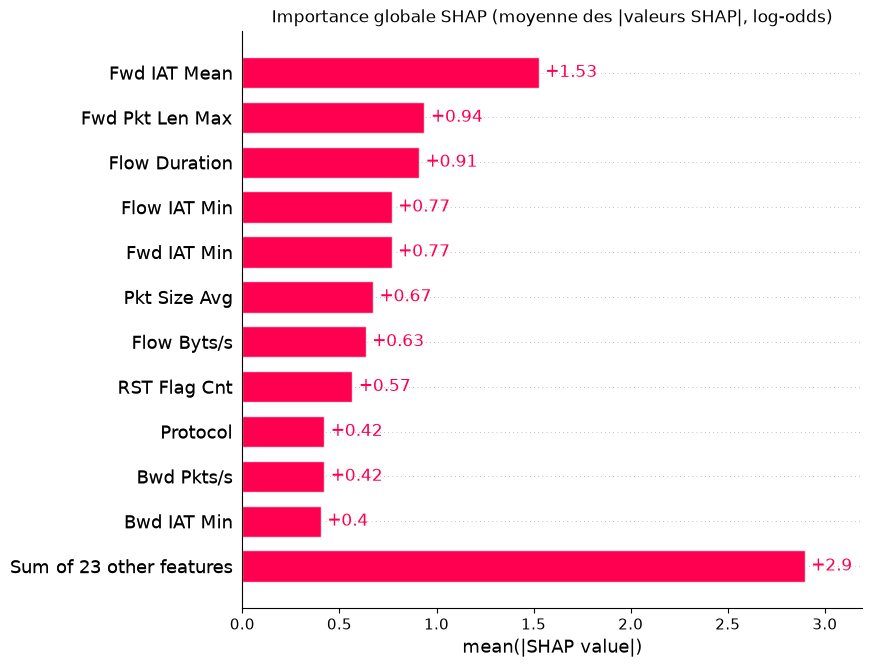

Fwd IAT Mean       1.526
Fwd Pkt Len Max    0.938
Flow Duration      0.910
Flow IAT Min       0.769
Fwd IAT Min        0.768
Pkt Size Avg       0.673
Flow Byts/s        0.635
RST Flag Cnt       0.566


In [6]:
# 5e – Graphique en barres
shap.plots.bar(sv, max_display=12, show=False)
plt.title("Importance globale SHAP (moyenne des |valeurs SHAP|, log-odds)")
plt.show()

importance_shap = pd.Series(np.abs(sv.values).mean(0), index=VARIABLES).sort_values(ascending=False)
print(importance_shap.head(8).round(3).to_string())

### Analyse – Graphique en barres
- Classement : `Fwd IAT Mean` (1,53), `Fwd Pkt Len Max` (0,94), `Flow Duration` (0,91), `Flow IAT Min`
  et `Fwd IAT Min` (0,77), `Pkt Size Avg` (0,67), `Flow Byts/s` (0,63), `RST Flag Cnt` (0,57).
- Trois familles de raisons : le **rythme** (intervalles entre paquets, durée), le **contenu** (taille
  des paquets, débit) et le **comportement TCP** (connexion coupée par RST).
- Au module 1, l'AUC univariée plaçait la taille des paquets en tête. SHAP montre que le modèle combine
  surtout le **rythme** ; la taille reste importante (6e).
- Les 23 autres variables cumulent 2,9 : l'importance est répartie entre variables corrélées.

### Graphique 2 – Nuage d'abeilles (beeswarm) : importance, sens et dispersion
Chaque point est un flux : position = valeur SHAP, couleur = valeur de la variable.
Les variables réseau ont des queues très lourdes (une durée va de 1 µs à 120 s) : colorées par leur
valeur brute, presque tous les points seraient bleus. On colore donc par le **rang** de la valeur
(bleu = parmi les plus faibles, rouge = parmi les plus fortes).

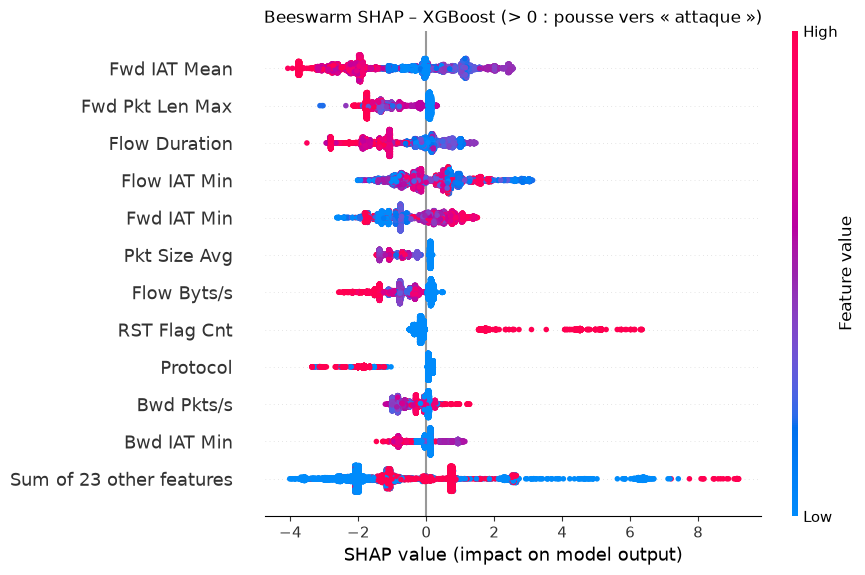

In [7]:
# 5f – Beeswarm (couleur = rang de la valeur)
sv_rangs = shap.Explanation(values=sv.values, base_values=sv.base_values,
                            data=X_num.rank(pct=True).to_numpy(), feature_names=VARIABLES)
shap.plots.beeswarm(sv_rangs, max_display=12, show=False)
plt.title("Beeswarm SHAP – XGBoost (> 0 : pousse vers « attaque »)")
plt.show()

### Analyse – Beeswarm
- **`Fwd IAT Mean`** : les valeurs élevées (rouge) sont très à gauche (jusqu'à −4) : un long intervalle
  entre deux paquets envoyés est un comportement humain. Les valeurs faibles à moyennes poussent vers
  l'attaque.
- **`Fwd Pkt Len Max`** : dès que le client envoie des données (violet, rouge), la contribution est
  négative (−1 à −2). Les flux sans aucune donnée (bleu) sont légèrement à droite.
- **`RST Flag Cnt`** : deux paquets de points. 0 est neutre ; 1 (rouge) donne **+2 à +6**, le signal le
  plus fort pour un flux donné (connexion coupée brutalement, typique du botnet).
- **`Protocol`** : UDP (rouge) donne −2 à −3. L'échantillon ne contient aucune attaque UDP : le modèle a
  appris « UDP = normal ». Un déni de service UDP passerait inaperçu (limite déjà notée au module 4).

### Graphique 3 – Dépendance : la forme de l'effet
Valeur SHAP d'une variable en fonction de sa valeur (échelle log), colorée par une seconde variable.

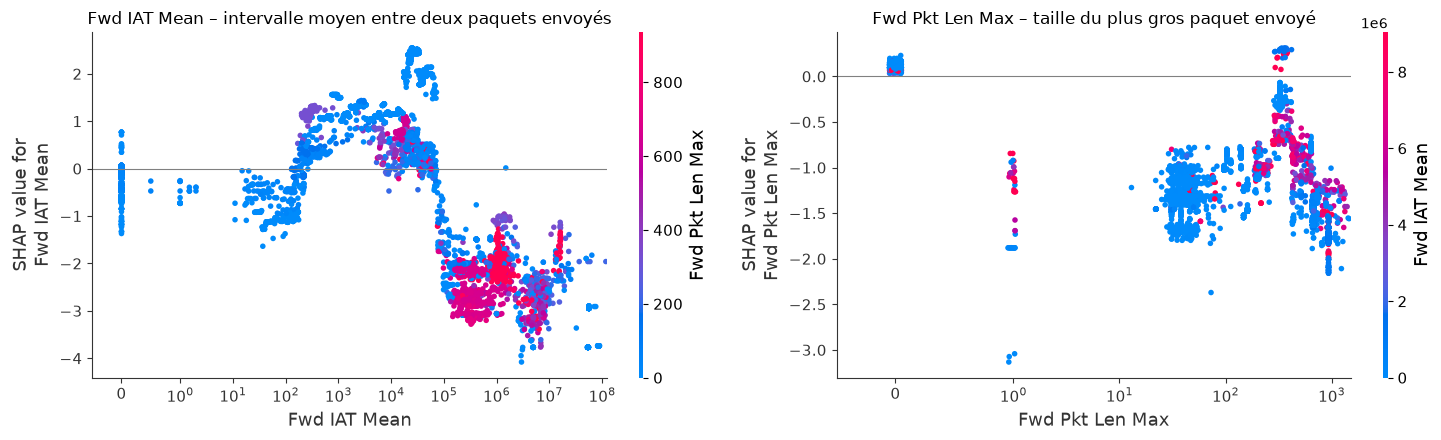

In [8]:
# 5g – Graphiques de dépendance des deux variables principales
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, (var, couleur) in zip(axes, [("Fwd IAT Mean", "Fwd Pkt Len Max"), ("Fwd Pkt Len Max", "Fwd IAT Mean")]):
    shap.plots.scatter(sv[:, var], color=sv[:, couleur], hist=False, ax=ax, show=False)
    ax.set_xscale("symlog", linthresh=1)
    ax.set_xlim(left=-0.5)
    ax.axhline(0, color="grey", lw=0.8)
    ax.set_title(f"{var} – {DESCRIPTIONS[var]}")
plt.tight_layout()
plt.show()

### Analyse – Dépendance
- **`Fwd IAT Mean`, effet en cloche** :
  - 0 µs (un seul paquet envoyé) : à peu près neutre ;
  - de 100 µs à 50 ms : **positif**, jusqu'à +2,5. C'est le rythme rapide et régulier des outils
    automatisés (Hulk envoie ses requêtes à quelques millisecondes d'intervalle) ;
  - au-delà d'environ 100 ms : **fortement négatif** (−2 à −4), l'attente d'un utilisateur.
- Comme dans le cours (Random Forest et durée du crédit), le modèle a appris des paliers et une zone de
  risque au milieu de la plage. Une régression logistique impose une droite : elle ne peut pas
  représenter cette cloche, ce qui explique une partie de son écart de performance.
- **`Fwd Pkt Len Max`** : 0 octet donne +0,1 ; dès qu'un octet de données est envoyé, la contribution
  tombe entre −1 et −2. Seule zone positive en dehors de 0 : vers 300–400 octets.

## 5.2 Explications locales

On choisit trois flux du test représentatifs pour l'analyste :
- une **attaque DoS Hulk détectée** (le type le plus fréquent) ;
- une **fausse alerte** (flux normal classé attaque) ;
- une **attaque manquée** (classée normale au seuil 0,8).

Attaque Hulk détectée – type réel : DoS attacks-Hulk | probabilité 0.984 → ATTAQUE (seuil 0.8)


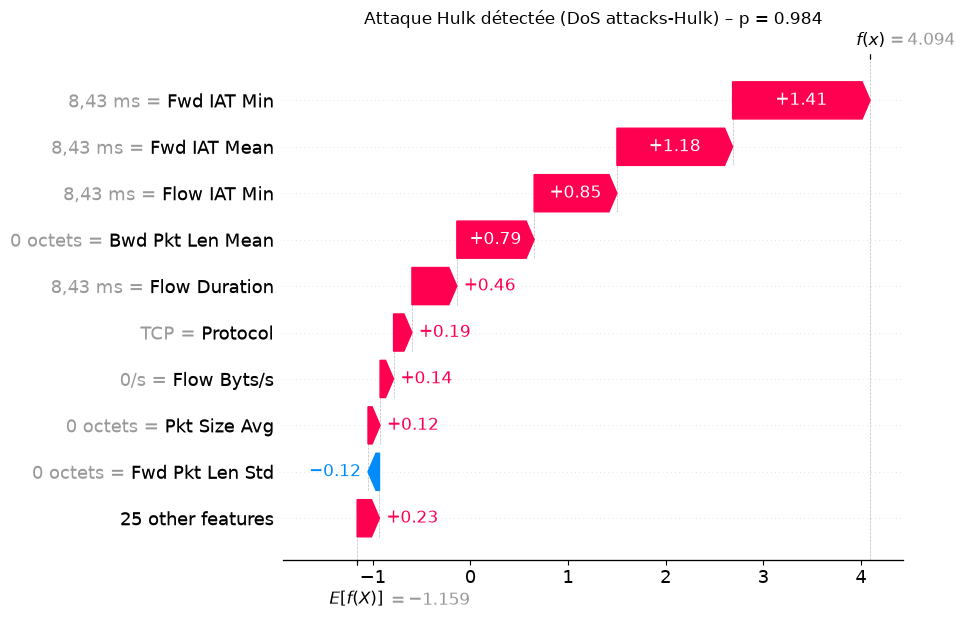

Fausse alerte – type réel : Benign | probabilité 0.998 → ATTAQUE (seuil 0.8)


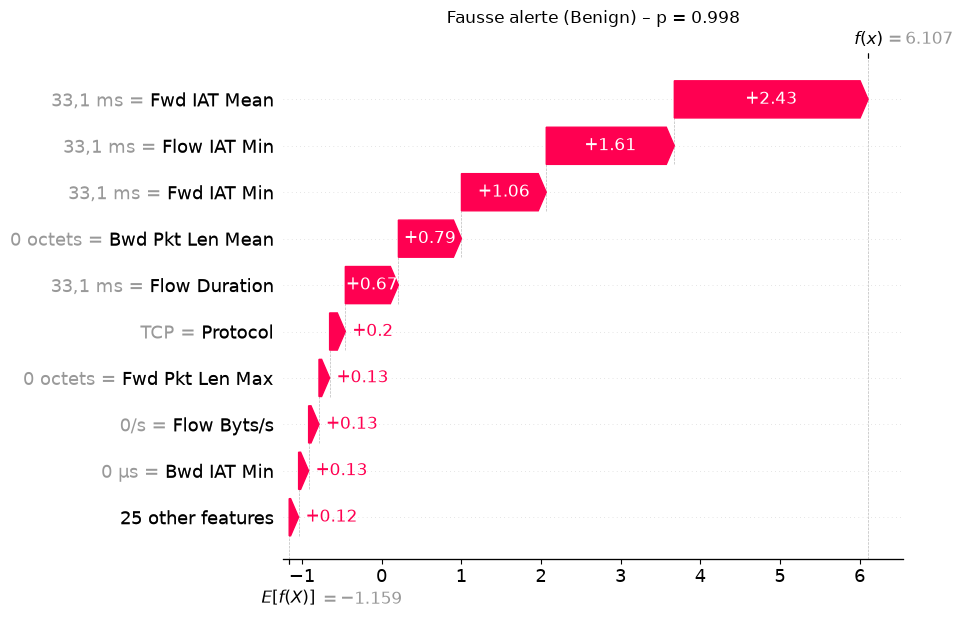

Attaque manquée – type réel : FTP-BruteForce | probabilité 0.796 → normal (seuil 0.8)


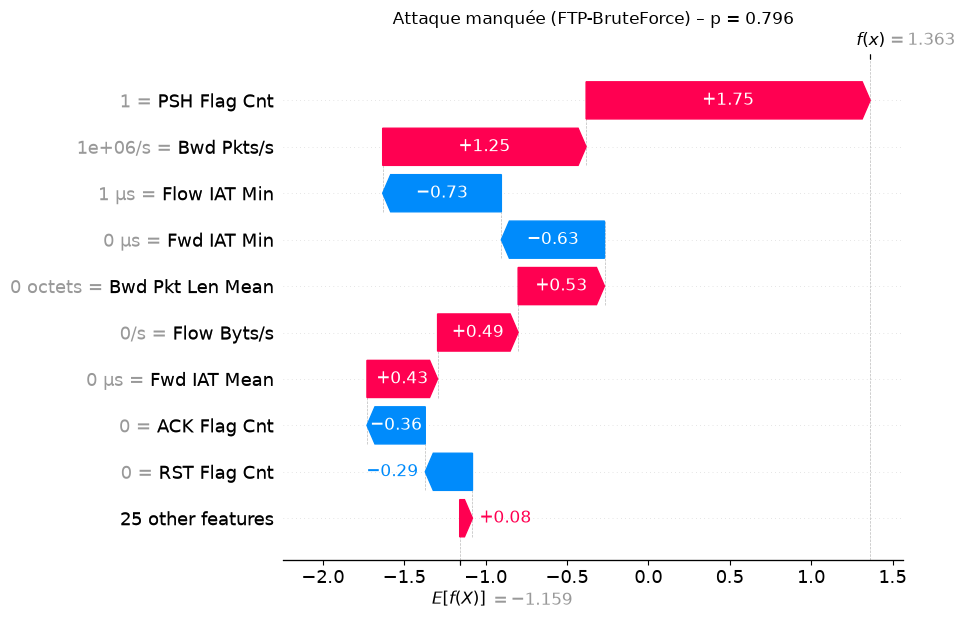

In [9]:
# 5h – Choix des flux et graphique 4 : cascade (waterfall)
alerte = p_xgb >= SEUIL_XAI
hulk = np.where((t_te == "DoS attacks-Hulk") & alerte)[0]
FLUX = {
    "Attaque Hulk détectée": hulk[np.argmin(np.abs(p_xgb[hulk] - np.median(p_xgb[hulk])))],
    "Fausse alerte": np.where((y_te == 0) & alerte)[0][np.argmax(p_xgb[(y_te == 0) & alerte])],
    "Attaque manquée": np.where((y_te == 1) & ~alerte)[0][np.argmax(p_xgb[(y_te == 1) & ~alerte])],
}


def cascade(i, titre, max_display=10):
    texte = np.array([lisible(v, x) for v, x in zip(VARIABLES, sv.data[i])], dtype=object)
    e = shap.Explanation(values=sv.values[i], base_values=sv.base_values[i], data=texte,
                         feature_names=VARIABLES)
    shap.plots.waterfall(e, max_display=max_display, show=False)
    plt.title(titre)
    plt.show()


for nom, i in FLUX.items():
    decision = "ATTAQUE" if p_xgb[i] >= SEUIL_XAI else "normal"
    print(f"{nom} – type réel : {t_te[i]} | probabilité {p_xgb[i]:.3f} → {decision} (seuil {SEUIL_XAI})")
    cascade(i, f"{nom} ({t_te[i]}) – p = {p_xgb[i]:.3f}")

### Analyse – Cascades (waterfall)
**Attaque Hulk détectée (98,4 %)** : on part de φ0 = −1,16 et on arrive à 4,09 log-odds.
- Les trois intervalles valent 8,4 ms (+1,41, +1,18, +0,85) : deux paquets envoyés à 8,4 ms d'écart.
- Le serveur ne renvoie aucun octet (`Bwd Pkt Len Mean` = 0, +0,79) et le flux dure 8,4 ms (+0,46).
- C'est le profil d'une requête Hulk restée sans réponse, sur un serveur saturé.

**Fausse alerte (flux normal, 99,8 %)** : exactement le même profil.
- Intervalles de 33,1 ms (+2,43, +1,61, +1,06), aucun octet renvoyé (+0,79), durée de 33 ms.
- Un flux normal court et sans réponse ressemble trait pour trait à Hulk. L'erreur est compréhensible
  et l'explication le montre à l'analyste : il lui suffit de vérifier si la source envoie une rafale
  (attaque) ou un flux isolé (fausse alerte).

**Attaque manquée (FTP-BruteForce, 79,6 %)** : juste sous le seuil (1,36 contre 1,39 en log-odds).
- `PSH Flag Cnt` = 1 (+1,75) et 1 million de paquets renvoyés par seconde (+1,25) poussent vers
  l'attaque.
- Les intervalles minimaux de 1 µs et 0 µs (−0,73, −0,63) la retiennent.
- Rappel du module 1 : FTP-BruteForce ne compte qu'une trentaine de flux uniques, en partie étiquetés
  aussi SlowHTTPTest. Le modèle a très peu d'exemples de cette attaque.

### Graphique 5 – Décision : les trajets de plusieurs flux
Chaque ligne est un flux : on part de φ0 en bas et on ajoute les contributions, des variables les moins
importantes (en bas) aux plus importantes (en haut). Le trait noir est le seuil 0,8 (1,39 en log-odds).

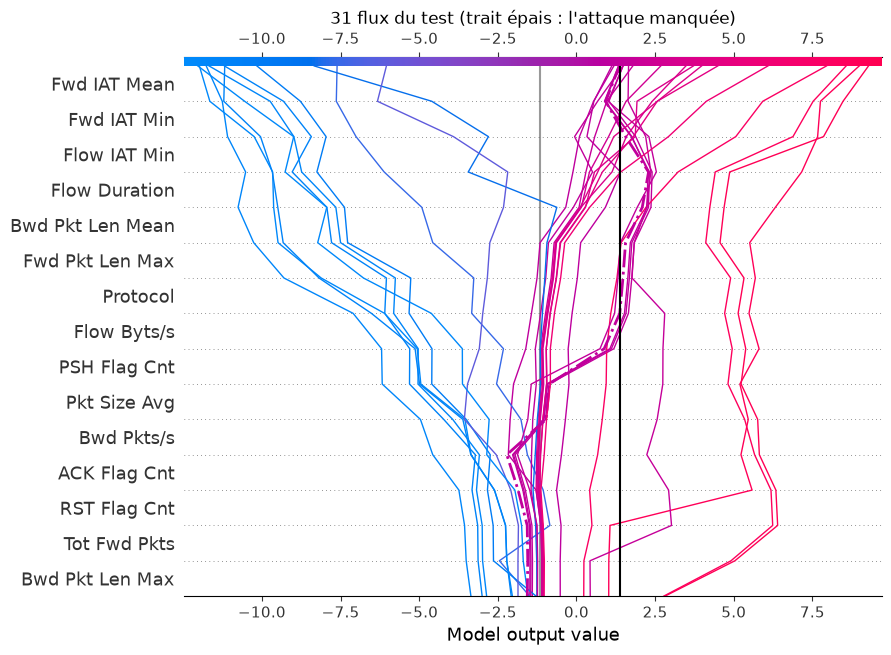

Flux les plus proches du seuil : {'FTP-BruteForce': 3, 'Benign': 3, 'DoS attacks-Hulk': 2, 'DoS attacks-SlowHTTPTest': 1, 'Bot': 1}


In [10]:
# 5i – Graphique de décision : 10 attaques, 10 flux normaux, 10 flux proches du seuil
rng = np.random.RandomState(1)
proches = np.argsort(np.abs(p_xgb - SEUIL_XAI))[:10]
choix = np.unique(np.concatenate([rng.choice(np.where(y_te == 1)[0], 10, replace=False),
                                  rng.choice(np.where(y_te == 0)[0], 10, replace=False), proches,
                                  [FLUX["Attaque manquée"]]]))
plt.figure(figsize=(9, 7))
shap.decision_plot(phi0, sv.values[choix], feature_names=VARIABLES, feature_display_range=slice(None, -16, -1),
                   highlight=[list(choix).index(FLUX["Attaque manquée"])], show=False, auto_size_plot=False)
plt.axvline(np.log(SEUIL_XAI / (1 - SEUIL_XAI)), color="black", lw=1.5)
plt.title("31 flux du test (trait épais : l'attaque manquée)")
plt.show()

types_proches = pd.Series(t_te[proches]).value_counts()
print("Flux les plus proches du seuil :", types_proches.to_dict())

### Analyse – Graphique de décision
- φ0 (trait gris) vaut −1,16 et le seuil (trait noir) +1,39. Comme dans le cours, les trajets restent
  groupés en bas (variables peu importantes) et s'écartent en haut : `Fwd IAT Mean`, `Fwd IAT Min`,
  `Flow IAT Min` et `Flow Duration` **font la décision**.
- Les flux normaux nets finissent vers −10, les attaques nettes entre +5 et +9 : très loin du seuil,
  donc peu d'incertitude.
- Zone grise : les 10 flux les plus proches du seuil sont 3 FTP-BruteForce, 3 normaux, 2 Hulk,
  1 SlowHTTPTest et 1 Bot. L'attaque manquée (trait épais) reste du côté normal jusqu'à `PSH Flag Cnt`,
  qui la fait remonter brusquement ; les variables de rythme la laissent juste sous le seuil.
- Pour l'analyste, ce graphique montre quelle variable fait basculer un dossier limite.

### LIME : un modèle linéaire autour du flux
Les 4 étapes du cours : (1) générer des voisins perturbés, (2) les faire prédire par XGBoost,
(3) les pondérer par leur proximité (noyau π_x), (4) ajuster une régression linéaire pondérée g.
On compare deux réglages du **noyau** : celui par défaut de LIME et un noyau étroit (vraiment local).

In [11]:
# 5j – LIME sur l'attaque Hulk, avec deux largeurs de noyau
ref = X_train_r.apply(pd.to_numeric, errors="coerce").astype(float)
ref = ref.fillna(ref.median())
i_prot = VARIABLES.index("Protocol")


def predire(tableau):
    df_ = pd.DataFrame(tableau, columns=VARIABLES)
    df_["Protocol"] = df_["Protocol"].round().astype(int).astype(str)   # retour au format du pipeline
    return xgb.predict_proba(df_)


def lime_flux(i, largeur_noyau=None, discretiseur="quartile"):
    explainer_lime = LimeTabularExplainer(
        ref.to_numpy(), feature_names=VARIABLES, class_names=["normal", "attaque"],
        categorical_features=[i_prot], discretize_continuous=True, discretizer=discretiseur,
        kernel_width=largeur_noyau, mode="classification", random_state=42)
    x = X_num.iloc[i].fillna(ref.median()).to_numpy()
    return explainer_lime.explain_instance(x, predire, num_features=10, num_samples=5000, labels=(1,))


i = FLUX["Attaque Hulk détectée"]
for titre, kw, disc in [("LIME par défaut (noyau 0,75·√34 ≈ 4,4, quartiles)", None, "quartile"),
                        ("LIME local (noyau 1, déciles)", 1.0, "decile")]:
    e = lime_flux(i, kw, disc)
    print(f"\n{titre}\n  prédiction de g : {float(np.ravel(e.local_pred)[0]):.2f} "
          f"(XGBoost : {p_xgb[i]:.2f}) | R² local : {e.score:.2f}")
    for regle, poids in e.as_list(label=1)[:6]:
        print(f"  {poids:+.3f}  {regle}")


LIME par défaut (noyau 0,75·√34 ≈ 4,4, quartiles)
  prédiction de g : 0.09 (XGBoost : 0.98) | R² local : 0.13
  -0.103  RST Flag Cnt <= 0.00
  -0.066  URG Flag Cnt <= 0.00
  +0.030  Protocol=6
  +0.028  Fwd Pkt Len Max <= 0.00
  +0.024  276.00 < Fwd IAT Mean <= 30347.00
  +0.023  2616.50 < Flow Duration <= 128179.50



LIME local (noyau 1, déciles)
  prédiction de g : 0.79 (XGBoost : 0.98) | R² local : 0.81
  +0.144  605.00 < Fwd IAT Min <= 9675.00
  +0.137  615.00 < Fwd IAT Mean <= 15835.14
  +0.131  1102.00 < Flow Duration <= 10065.00
  +0.122  2888.00 < Flow IAT Min <= 27273.00
  +0.094  Fwd Pkt Len Max <= 0.00
  +0.086  TotLen Fwd Pkts <= 0.00


### Analyse – LIME
- **Réglage par défaut** : g prédit 0,09 alors que XGBoost dit 0,98, avec un R² local de 0,13. Les règles
  (`RST Flag Cnt ≤ 0`, `URG Flag Cnt ≤ 0`) sont presque les mêmes pour tous les flux. Le noyau est
  trop large (voisins tirés dans tout l'espace) : l'explication devient globale et n'est **pas fidèle**.
- **Noyau étroit** : g prédit 0,79 avec un R² de 0,81. Les règles retrouvent les 4 variables de rythme
  (entre 0,6 et 27 ms) et l'absence de données envoyées (`Fwd Pkt Len Max ≤ 0`, `TotLen Fwd Pkts ≤ 0`),
  ce qui est cohérent avec SHAP.
- Leçon : LIME dépend fortement de la définition du voisinage. Il faut regarder le R² et la prédiction
  locale avant de croire l'explication.
- Unités : les poids LIME sont en points de probabilité (+0,144 = +14 points), SHAP en log-odds.

In [12]:
# 5k – SHAP et LIME donnent-ils les mêmes raisons ? (50 flux, top 5 de chaque méthode)
def top5_shap(i):
    s = pd.Series(sv.values[i], index=VARIABLES)
    return s.reindex(s.abs().sort_values(ascending=False).index[:5])


def accord(i, kw, disc):
    e = lime_flux(i, kw, disc)
    lime_ = {VARIABLES[j]: w for j, w in e.as_map()[1][:5]}
    s = top5_shap(i)
    communes = [v for v in s.index if v in lime_]
    meme_sens = [v for v in communes if np.sign(s[v]) == np.sign(lime_[v])]
    return len(communes), len(meme_sens), e.score, abs(float(np.ravel(e.local_pred)[0]) - p_xgb[i])


rng = np.random.RandomState(42)
cinquante = np.concatenate([rng.choice(np.where(y_te == 1)[0], 25, replace=False),
                            rng.choice(np.where(y_te == 0)[0], 25, replace=False)])
lignes = []
for nom, kw, disc in [("défaut", None, "quartile"), ("local", 1.0, "decile")]:
    r = np.array([accord(i, kw, disc) for i in cinquante])
    lignes.append({"LIME": nom, "variables communes (sur 5)": r[:, 0].mean(),
                   "même sens (sur 5)": r[:, 1].mean(), "R² local": r[:, 2].mean(),
                   "écart à la proba XGBoost": r[:, 3].mean()})
print(pd.DataFrame(lignes).set_index("LIME").round(2).to_string())

# Comparaison détaillée sur la fausse alerte
i = FLUX["Fausse alerte"]
e = lime_flux(i, 1.0, "decile")
lime_fa = pd.Series({VARIABLES[j]: w for j, w in e.as_map()[1]})
comp = pd.DataFrame({"SHAP (log-odds)": top5_shap(i)}).join(lime_fa.rename("LIME (probabilité)"), how="outer")
print("\nFausse alerte – top 5 SHAP et poids LIME :")
print(comp.reindex(comp["SHAP (log-odds)"].abs().sort_values(ascending=False).index).round(3).to_string())

        variables communes (sur 5)  même sens (sur 5)  R² local  écart à la proba XGBoost
LIME                                                                                     
défaut                        1.46               1.36      0.13                      0.47
local                         2.80               2.76      0.42                      0.07



Fausse alerte – top 5 SHAP et poids LIME :
                  SHAP (log-odds)  LIME (probabilité)
Fwd IAT Mean                2.432               0.122
Flow IAT Min                1.607               0.126
Fwd IAT Min                 1.064               0.129
Bwd Pkt Len Mean            0.791                 NaN
Flow Duration               0.666               0.135
ACK Flag Cnt                  NaN               0.060
Flow Byts/s                   NaN               0.087
Fwd Pkt Len Max               NaN               0.096
Pkt Size Avg                  NaN               0.086
RST Flag Cnt                  NaN              -0.007
TotLen Fwd Pkts               NaN               0.087


### Analyse – Cohérence SHAP / LIME
- Sur 50 flux, LIME local retrouve en moyenne **2,8 des 5 variables principales de SHAP**, presque
  toujours avec le même sens (2,76). LIME par défaut n'en retrouve que 1,5.
- Fausse alerte : 4 variables communes sur 5 (`Fwd IAT Mean`, `Flow IAT Min`, `Fwd IAT Min`,
  `Flow Duration`), toutes dans le même sens. LIME ajoute plusieurs « 0 » (aucune donnée envoyée,
  débit nul, taille moyenne faible) : c'est la même information que `Bwd Pkt Len Mean` chez SHAP. Avec
  des variables corrélées, les deux méthodes répartissent le crédit différemment.
- **Cohérence avec l'intuition métier** : oui. Un rythme rapide et régulier, sans données échangées,
  correspond à un outil automatisé.
- SHAP (TreeExplainer) est exact, additif et déterministe ; LIME est aléatoire et sensible à son
  noyau. On garde SHAP pour l'application et l'API, et LIME comme second avis.

### Phrase de synthèse automatique
On garde les deux variables qui poussent le plus dans le sens de la décision, avec leur valeur et la
médiane du trafic normal pour donner un point de comparaison à l'analyste.

In [13]:
# 5l – Phrase de synthèse
medianes_normal = X_train_r[np.asarray(y_train) == 0].apply(pd.to_numeric, errors="coerce").median()


def phrase(i, seuil=SEUIL_XAI, k=2):
    p = p_xgb[i]
    attaque = p >= seuil
    s = pd.Series(sv.values[i], index=VARIABLES)
    s = s[s > 0] if attaque else s[s < 0]
    raisons = []
    for v in s.abs().sort_values(ascending=False).index[:k]:
        raisons.append(f"{DESCRIPTIONS.get(v, v)} = {lisible(v, sv.data[i][VARIABLES.index(v)])} "
                       f"(médiane du trafic normal : {lisible(v, medianes_normal[v])})")
    proba = f"{p * 100:.1f} %".replace(".", ",")
    debut = (f"Le risque d'attaque est élevé ({proba}) principalement à cause de" if attaque
             else f"Le flux est jugé normal ({proba} de risque) surtout grâce à")
    return f"{debut} : " + " ; ".join(raisons) + "."


for nom, i in FLUX.items():
    print(f"{nom} ({t_te[i]}) :\n  {phrase(i)}\n")

Attaque Hulk détectée (DoS attacks-Hulk) :
  Le risque d'attaque est élevé (98,4 %) principalement à cause de : intervalle minimal entre deux paquets envoyés = 8,43 ms (médiane du trafic normal : 31 µs) ; intervalle moyen entre deux paquets envoyés = 8,43 ms (médiane du trafic normal : 256 ms).

Fausse alerte (Benign) :
  Le risque d'attaque est élevé (99,8 %) principalement à cause de : intervalle moyen entre deux paquets envoyés = 33,1 ms (médiane du trafic normal : 256 ms) ; intervalle minimal entre deux paquets = 33,1 ms (médiane du trafic normal : 27 µs).

Attaque manquée (FTP-BruteForce) :
  Le flux est jugé normal (79,6 % de risque) surtout grâce à : intervalle minimal entre deux paquets = 1 µs (médiane du trafic normal : 27 µs) ; intervalle minimal entre deux paquets envoyés = 0 µs (médiane du trafic normal : 31 µs).



### Analyse – Phrase de synthèse
- Les phrases donnent à l'analyste les deux raisons principales, avec un point de comparaison
  (« 8,43 ms, contre 256 ms en médiane pour le trafic normal »).
- Elles montrent aussi les limites : pour l'attaque manquée, l'argument « intervalle minimal de
  1 µs » est peu intuitif. Il reflète ce que le modèle a appris sur très peu d'exemples FTP, pas une
  règle métier.

## 5.3 Analyse critique

### Les modèles s'appuient-ils sur les mêmes raisons ?
SHAP s'applique à chaque modèle avec l'explainer adapté (cours : `LinearExplainer` pour la régression
logistique, `TreeExplainer` pour les arbres). On compare sur la même attaque Hulk.

In [14]:
# 5m – Même flux, trois modèles
i = FLUX["Attaque Hulk détectée"]
lr = modeles_finaux["Régression logistique"]
prep_lr = lr.named_steps["prep"]
fond = prep_lr.transform(X_train_r.sample(200, random_state=42))
sv_lr = shap.LinearExplainer(lr.named_steps["modele"], fond)(prep_lr.transform(X_test_r.iloc[[i]]))
contrib_lr = pd.Series(sv_lr.values[0], index=origine_des_colonnes(lr)).groupby(level=0).sum()

rf = modeles_finaux["Random Forest"]
sv_rf = shap.TreeExplainer(rf.named_steps["modele"])(rf.named_steps["prep"].transform(X_test_r.iloc[[i]]))
contrib_rf = pd.Series(sv_rf.values[0, :, 1], index=origine_des_colonnes(rf)).groupby(level=0).sum()

for nom, c, p, unite in [("XGBoost", pd.Series(sv.values[i], index=VARIABLES), p_xgb[i], "log-odds"),
                         ("Random Forest", contrib_rf, rf.predict_proba(X_test_r.iloc[[i]])[0, 1], "probabilité"),
                         ("Régression logistique", contrib_lr, lr.predict_proba(X_test_r.iloc[[i]])[0, 1], "log-odds")]:
    top = c.reindex(c.abs().sort_values(ascending=False).index[:4])
    print(f"{nom:<22} p = {p:.2f} | " + ", ".join(f"{v} ({x:+.2f})" for v, x in top.items()) + f"  [{unite}]")

XGBoost                p = 0.98 | Fwd IAT Min (+1.41), Fwd IAT Mean (+1.18), Flow IAT Min (+0.85), Bwd Pkt Len Mean (+0.79)  [log-odds]
Random Forest          p = 0.96 | Flow Duration (+0.11), Bwd Pkt Len Mean (+0.09), Fwd IAT Mean (+0.08), Fwd IAT Min (+0.07)  [probabilité]
Régression logistique  p = 0.73 | Pkt Size Avg (+54.71), Pkt Len Std (-44.30), Fwd Pkt Len Std (-39.43), TotLen Fwd Pkts (+38.20)  [log-odds]


### Analyse – Comparaison des modèles
- **XGBoost et Random Forest sont d'accord** : le rythme (`Fwd IAT Min`, `Fwd IAT Mean`,
  `Flow Duration`) et l'absence de réponse (`Bwd Pkt Len Mean`). Les valeurs de Random Forest sont en
  probabilité, celles de XGBoost en log-odds.
- **La régression logistique** produit des contributions énormes qui se compensent (+54,7, −44,3,
  −39,4, +38,2 log-odds) pour une prédiction finale de 0,73. C'est l'effet de la colinéarité (les
  tailles de paquets sont très corrélées) et d'une régularisation faible (C = 100).
- Ses coefficients, « lisibles » en théorie, ne sont donc **pas interprétables tels quels** : ici, le
  modèle simple n'est pas plus explicable que XGBoost, et il est moins performant.

### Variables sensibles et équité : le test de l'empreinte système
Le jeu ne contient aucune donnée personnelle (adresses IP exclues dès le module 1). Le risque équivalent
est un **raccourci** : des variables qui identifient la *machine* de l'attaquant plutôt que son
*comportement*. On réentraîne XGBoost en remettant les trois variables d'empreinte et on regarde SHAP.

In [15]:
# 5n – Modèle avec empreinte système (nécessite df, le jeu nettoyé du module 1)
from sklearn.metrics import average_precision_score
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline

EMPREINTE = ["Init Fwd Win Byts", "Init Bwd Win Byts", "Fwd Seg Size Min"]
if "df" not in globals():
    print("Relancez d'abord les cellules du module 1 (nettoyage) pour disposer de df.")
else:
    X_tr_e = X_train_r.join(df.loc[X_train_r.index, EMPREINTE])
    X_te_e = X_test_r.join(df.loc[X_test_r.index, EMPREINTE])
    xgb_e = Pipeline([("prep", construire_preprocesseur(X_tr_e, True, True)),
                      ("modele", XGBClassifier(n_estimators=200, max_depth=5, learning_rate=0.1,
                                               eval_metric="logloss", random_state=42))])
    xgb_e.fit(X_tr_e, y_train)
    pr_auc_e = average_precision_score(y_te, xgb_e.predict_proba(X_te_e)[:, 1])
    print(f"PR-AUC test : {average_precision_score(y_te, p_xgb):.4f} sans empreinte → {pr_auc_e:.4f} avec")

    pe = xgb_e.named_steps["prep"]
    vars_e = list(X_te_e.columns)
    origine_e = [n.split("__", 1)[1] if n.split("__", 1)[1] in vars_e else n.split("__", 1)[1].rsplit("_", 1)[0]
                 for n in pe.get_feature_names_out()]
    sv_e = shap.TreeExplainer(xgb_e.named_steps["modele"])(pe.transform(X_te_e))
    imp_e = pd.Series(np.abs(sv_e.values).mean(0), index=origine_e).groupby(level=0).sum()
    imp_e = imp_e.sort_values(ascending=False)
    print("\nImportance SHAP – modèle avec empreinte :")
    print(imp_e.head(6).round(3).to_string())
    print(f"\nPart de l'importance totale portée par l'empreinte : {imp_e[EMPREINTE].sum() / imp_e.sum():.0%}")
    print("\nTaux d'attaque par valeur de la fenêtre TCP initiale (5 valeurs les plus fréquentes) :")
    print(X_te_e.assign(attaque=y_te).groupby("Init Fwd Win Byts")["attaque"].agg(["mean", "size"])
          .sort_values("size", ascending=False).head(5).round(3).to_string())

PR-AUC test : 0.9936 sans empreinte → 0.9997 avec



Importance SHAP – modèle avec empreinte :
Fwd Seg Size Min     2.111
Init Fwd Win Byts    2.000
Fwd IAT Mean         1.448
Fwd Pkt Len Max      1.300
RST Flag Cnt         0.817
Flow Duration        0.746

Part de l'importance totale portée par l'empreinte : 36%

Taux d'attaque par valeur de la fenêtre TCP initiale (5 valeurs les plus fréquentes) :
                    mean  size
Init Fwd Win Byts             
 8192              0.187  2236
-1                 0.001  1237
 225               1.000  1198
 219               0.001   791
 237               0.000   553


### Analyse – Raccourci « empreinte système »
- Avec l'empreinte, la PR-AUC passe de 0,9936 à **0,9997** : un gain en apparence.
- Mais les deux premières variables SHAP deviennent `Fwd Seg Size Min` (2,11) et `Init Fwd Win Byts`
  (2,00), qui portent **36 % de l'importance totale**.
- Une fenêtre TCP initiale de 225 donne **100 % d'attaques** sur 1 198 flux. Ce n'est pas un
  comportement : c'est la signature de la pile TCP des machines attaquantes du laboratoire.
- Dans un vrai réseau, toutes les machines légitimes du même système seraient suspectées, et un
  attaquant qui change de système passerait. C'est l'équivalent d'une **variable sensible** : décider
  sur *qui* émet plutôt que sur *ce qu'il fait*. L'exclusion décidée au module 1 est justifiée, et
  SHAP permet de détecter ce type de raccourci.

## Bilan du module 5 – Explainable AI

| Question | Réponse |
|---|---|
| Sur quoi le modèle décide-t-il ? | Le **rythme** des paquets (`Fwd IAT Mean`, intervalles minimaux, durée), puis le **contenu** (taille, aucune donnée) et les **connexions coupées** (RST). Effets non linéaires (cloche). |
| Pourquoi ce flux ? | Cascade et graphique de décision SHAP, phrase de synthèse avec les deux raisons principales. |
| SHAP et LIME sont-ils cohérents ? | Oui si LIME est réglé localement : ≈ 3 variables sur 5 en commun, même sens. LIME par défaut est trompeur (R² 0,13). |
| Variables sensibles, équité | Aucune donnée personnelle. Le raccourci « empreinte système » (36 % de l'importance s'il est gardé) est détecté et exclu. « UDP = normal » est un biais d'échantillon à surveiller. |
| Performance ou interprétabilité ? | La régression logistique est moins performante **et** ses contributions se compensent (±50 log-odds) : XGBoost + SHAP est le meilleur compromis. |
| Actions pour le décideur | Afficher l'explication de chaque alerte ; qualifier les flux courts sans réponse en agrégeant par source ; ajouter des attaques UDP et FTP à l'entraînement ; surveiller la dérive des variables de rythme. |